# Microgrid Preprocessing — Pecan Street Dataset
### From raw CSV → clean, normalized, analysis-ready data
Run cells top to bottom. No prior state needed.

## 1. Imports & Config

In [ ]:
# ===== MASTER SETUP (run first after every runtime restart) =====
import os, random, zipfile, shutil, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
from google.colab import files, drive

SEED = 42
INTERVAL = 15
MIN_DAYS = 60

# Resume controls:
# 1) Set RESUME_RUN_DIR to a specific previous run path, OR
# 2) Keep it blank and set AUTO_RESUME_LATEST=True to auto-pick latest run, OR
# 3) Disable auto resume to always create a fresh run.
RESUME_RUN_DIR = ''
AUTO_RESUME_LATEST = True

# Mount Drive for persistence
drive.mount('/content/drive', force_remount=True)

RUNS_BASE = '/content/drive/MyDrive/microgrid_runs'
os.makedirs(RUNS_BASE, exist_ok=True)

run_dirs = sorted([
    os.path.join(RUNS_BASE, d)
    for d in os.listdir(RUNS_BASE)
    if d.startswith('run_') and os.path.isdir(os.path.join(RUNS_BASE, d))
])

if RESUME_RUN_DIR and os.path.exists(RESUME_RUN_DIR):
    RUN_DIR = RESUME_RUN_DIR
    run_mode = 'resume-explicit'
elif AUTO_RESUME_LATEST and len(run_dirs) > 0:
    RUN_DIR = run_dirs[-1]
    run_mode = 'resume-latest'
else:
    RUN_DIR = os.path.join(RUNS_BASE, f"run_{time.strftime('%Y%m%d_%H%M%S')}")
    os.makedirs(RUN_DIR, exist_ok=True)
    run_mode = 'new-run'

SAVE_DIR_ABLATION = os.path.join(RUN_DIR, 'artifacts_ablation')
os.makedirs(SAVE_DIR_ABLATION, exist_ok=True)
os.makedirs(os.path.join(RUN_DIR, 'keras_ckpts'), exist_ok=True)
os.makedirs(os.path.join(RUN_DIR, 'sac_ckpts'), exist_ok=True)

# Data path strategy: resume from saved copy if present, otherwise upload once and persist it.
dataset_copy = os.path.join(RUN_DIR, 'input_dataset.csv')
if os.path.exists(dataset_copy):
    CSV_PATH = dataset_copy
    print('Using persisted dataset copy from RUN_DIR')
else:
    uploaded = files.upload()  # choose your CSV file from laptop
    uploaded_name = next(iter(uploaded))
    temp_csv_path = f"/content/{uploaded_name}"
    shutil.copy(temp_csv_path, dataset_copy)
    CSV_PATH = dataset_copy
    print(f'Dataset copied to {dataset_copy}')

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED'] = str(SEED)

print('Setup OK')
print('Run mode =', run_mode)
print('RUN_DIR =', RUN_DIR)
print('TensorFlow:', tf.__version__)
print('Pandas:', pd.__version__)
print('CSV_PATH =', CSV_PATH)
print('CSV exists:', os.path.exists(CSV_PATH))
print('Found prior runs:', len(run_dirs))
if len(run_dirs) > 0:
    print('Latest run:', run_dirs[-1])
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f'CSV not found at: {CSV_PATH}')

Mounted at /content/drive
Using persisted dataset copy from RUN_DIR
Setup OK
Run mode = resume-latest
RUN_DIR = /content/drive/MyDrive/microgrid_runs/run_20260406_174947
TensorFlow: 2.19.0
Pandas: 2.2.2
CSV_PATH = /content/drive/MyDrive/microgrid_runs/run_20260406_174947/input_dataset.csv
CSV exists: True
Found prior runs: 1
Latest run: /content/drive/MyDrive/microgrid_runs/run_20260406_174947


## 2. Load Raw Data

In [ ]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False)
# Convert to string first to ensure uniform input for to_datetime, handling potential mixed types
df_raw['local_15min'] = df_raw['local_15min'].astype(str)
# Convert to datetime, coercing errors. The sample data suggests it will become timezone-aware.
df_raw['local_15min'] = pd.to_datetime(df_raw['local_15min'], utc=False, format='mixed', dayfirst=False, errors='coerce')

# Drop rows where datetime conversion failed (where 'local_15min' is NaT)
df_raw.dropna(subset=['local_15min'], inplace=True)

# Strip timezone so comparisons are simple. Use tz_convert(None) for already timezone-aware series.
# This will make the column timezone-naive if it was timezone-aware.
# If it is already naive, this operation will have no effect.
if not df_raw['local_15min'].empty and df_raw['local_15min'].dt.tz is not None:
    df_raw['local_15min'] = df_raw['local_15min'].dt.tz_convert(None)

bad_dates = (
    (df_raw['local_15min'] >= '2019-05-25') & (df_raw['local_15min'] < '2019-06-24')
) | (
    (df_raw['local_15min'] >= '2019-08-14') & (df_raw['local_15min'] < '2019-08-16')
) | (
    df_raw['local_15min'].dt.date == pd.Timestamp('2019-10-29').date()
)

df_raw = df_raw[~bad_dates].copy()

print(f'Raw shape : {df_raw.shape}')
print(f'Date range: {df_raw["local_15min"].min()}  →  {df_raw["local_15min"].max()}')
print(f'Houses    : {df_raw["dataid"].nunique()}')
df_raw.head(3)

Raw shape : (362399, 79)
Date range: 2019-05-01 05:00:00  →  2019-11-01 04:45:00
Houses    : 25


## 3. Build total_solar & total_load columns

In [ ]:
# ── Solar: sum solar + solar2 (both can exist)
solar_cols = [c for c in ['solar', 'solar2'] if c in df_raw.columns]
print(f'Solar columns found: {solar_cols}')
df_raw['total_solar'] = df_raw[solar_cols].fillna(0).sum(axis=1).clip(lower=0)

# ── Load: sum every appliance column (exclude meta/solar/grid/voltage cols)
exclude = {'dataid', 'local_15min', 'grid', 'leg1v', 'leg2v',
           'solar', 'solar2', 'total_solar'}
appliance_cols = [c for c in df_raw.columns if c not in exclude]
df_raw['total_load'] = df_raw[appliance_cols].fillna(0).sum(axis=1).clip(lower=0)

# ── Net load = demand − supply  (positive = needs energy, negative = surplus)
df_raw['net_load'] = df_raw['total_load'] - df_raw['total_solar']

print(f'Appliance columns used for load: {len(appliance_cols)}')
df_raw[['total_load', 'total_solar', 'net_load']].describe().round(3)

Solar columns found: ['solar', 'solar2']
Appliance columns used for load: 72


## 4. Find all SOLAR houses + how many days each has

In [ ]:
# A house is a 'solar house' if it has at least one non-zero solar reading
solar_summary = (
    df_raw[df_raw['total_solar'] > 0]
    .groupby('dataid')
    .agg(
        first_date   = ('local_15min', 'min'),
        last_date    = ('local_15min', 'max'),
        total_records= ('local_15min', 'count'),
        peak_solar   = ('total_solar',  'max'),
        avg_solar    = ('total_solar',  'mean'),
        avg_load     = ('total_load',   'mean'),
        avg_net_load = ('net_load',     'mean'),
        load_volatility = ('total_load','std'),
    )
    .assign(
        days_of_data = lambda x: (x['last_date'] - x['first_date']).dt.days,
        expected_records = lambda x: x['days_of_data'] * (24 * 60 // INTERVAL),
        completeness_pct = lambda x: (x['total_records'] / x['expected_records'] * 100).round(1)
    )
    .sort_values('days_of_data', ascending=False)
)

print(f'Total solar houses found: {len(solar_summary)}')
print()
print(solar_summary[['days_of_data','total_records','completeness_pct',
                      'peak_solar','avg_solar','avg_load','load_volatility']].to_string())

Total solar houses found: 14

        days_of_data  total_records  completeness_pct  peak_solar  avg_solar  avg_load  load_volatility
dataid                                                                                                 
27               183           7887              44.9      11.615   3.622094  0.805287         0.941124
142              183           7817              44.5       5.026   1.669364  0.446557         0.326839
387              183           7466              42.5       2.900   1.028608  0.266290         0.304471
914              183           8323              47.4       9.297   2.269325  0.266846         0.806123
950              183           7694              43.8      18.244   5.770764  2.124008         1.785090
1222             183           7920              45.1       5.550   1.688344  0.841102         1.614510
1240             183           7813              44.5       9.994   3.206560  0.708541         0.798448
3000             183           962

## 5. Filter: keep only houses with ≥ MIN_DAYS of solar data

In [ ]:
good_houses = solar_summary[solar_summary['days_of_data'] >= MIN_DAYS].index.tolist()
print(f'Houses with ≥ {MIN_DAYS} days of solar data: {len(good_houses)}')
print(good_houses)

# Keep only those houses in our working dataframe
df = df_raw[df_raw['dataid'].isin(good_houses)].copy()
df = df.sort_values(['dataid', 'local_15min']).reset_index(drop=True)
print(f'Working dataframe shape: {df.shape}')

Houses with ≥ 60 days of solar data: 14
[27, 142, 387, 914, 950, 1222, 1240, 3000, 3488, 3517, 5058, 5587, 5679, 5997]
Working dataframe shape: (202943, 82)


## 6. Visual: Days of data per solar house (bar chart)

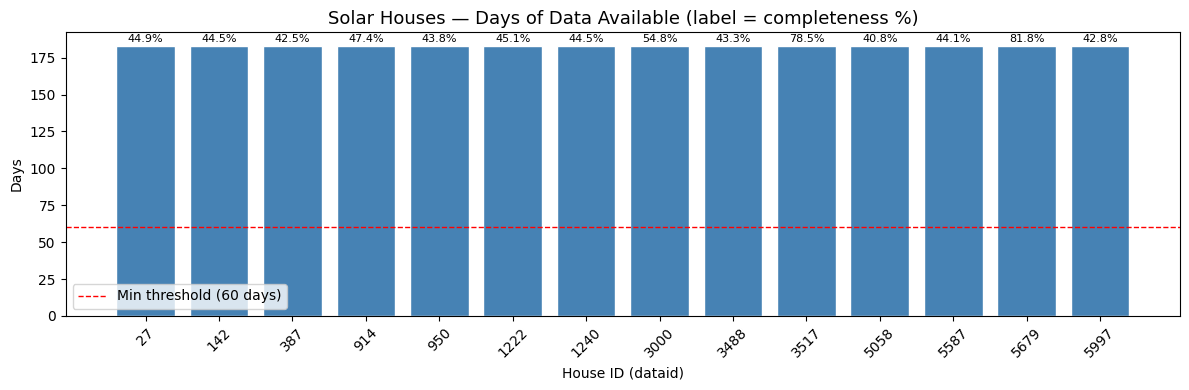

In [ ]:
plot_data = solar_summary[solar_summary['days_of_data'] >= MIN_DAYS].copy()

fig, ax = plt.subplots(figsize=(12, 4))
bars = ax.bar(plot_data.index.astype(str), plot_data['days_of_data'], color='steelblue', edgecolor='white')
ax.axhline(MIN_DAYS, color='red', linestyle='--', linewidth=1, label=f'Min threshold ({MIN_DAYS} days)')

# Label each bar with completeness %
for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{row['completeness_pct']}%", ha='center', va='bottom', fontsize=8)

ax.set_title('Solar Houses — Days of Data Available (label = completeness %)', fontsize=13)
ax.set_xlabel('House ID (dataid)')
ax.set_ylabel('Days')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Per-house energy profile plots (Load vs Solar, Net Load)

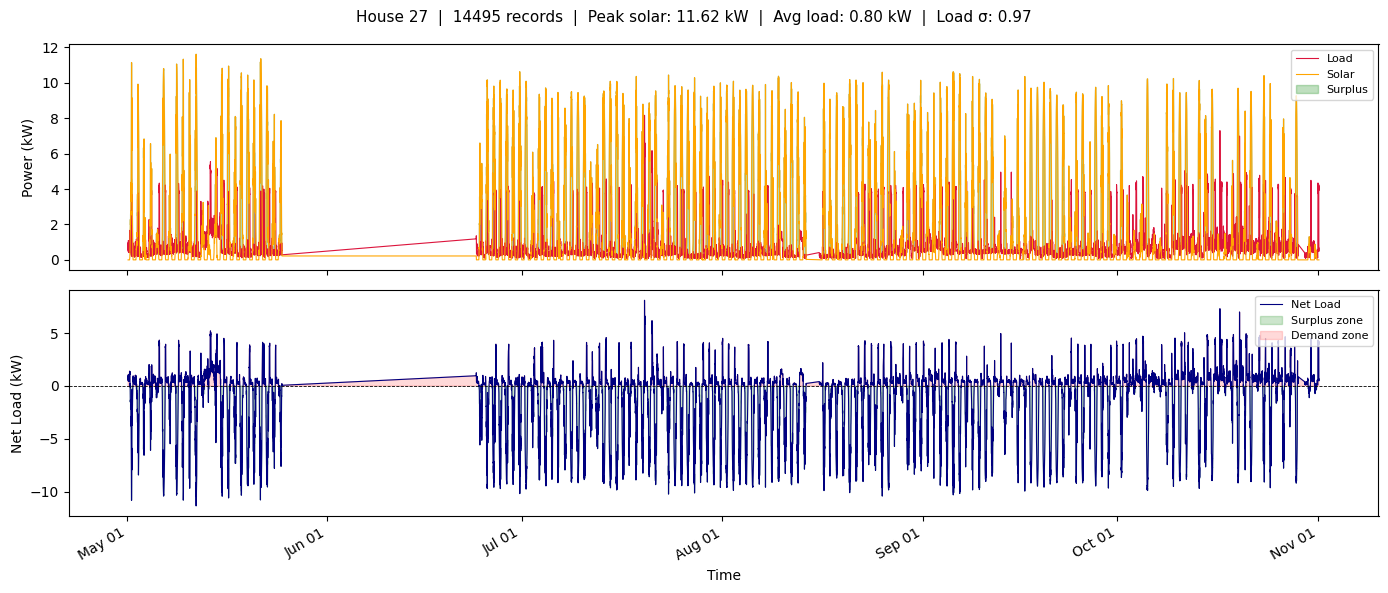

----------------------------------------------------------------------


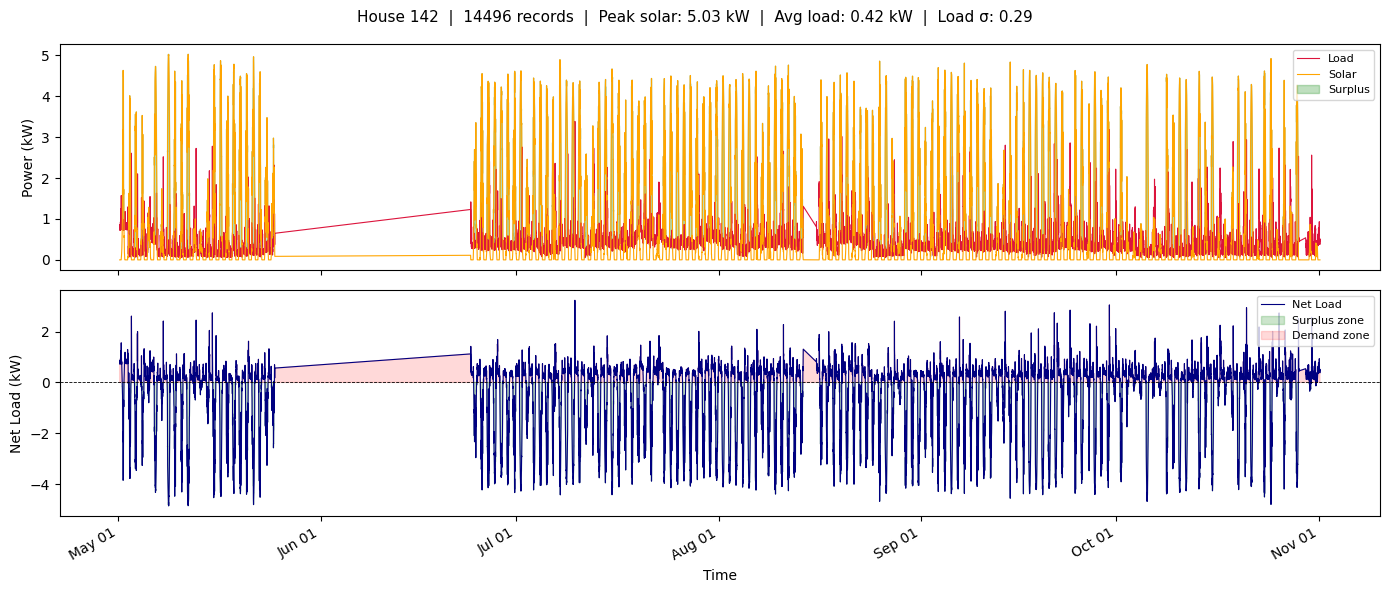

----------------------------------------------------------------------


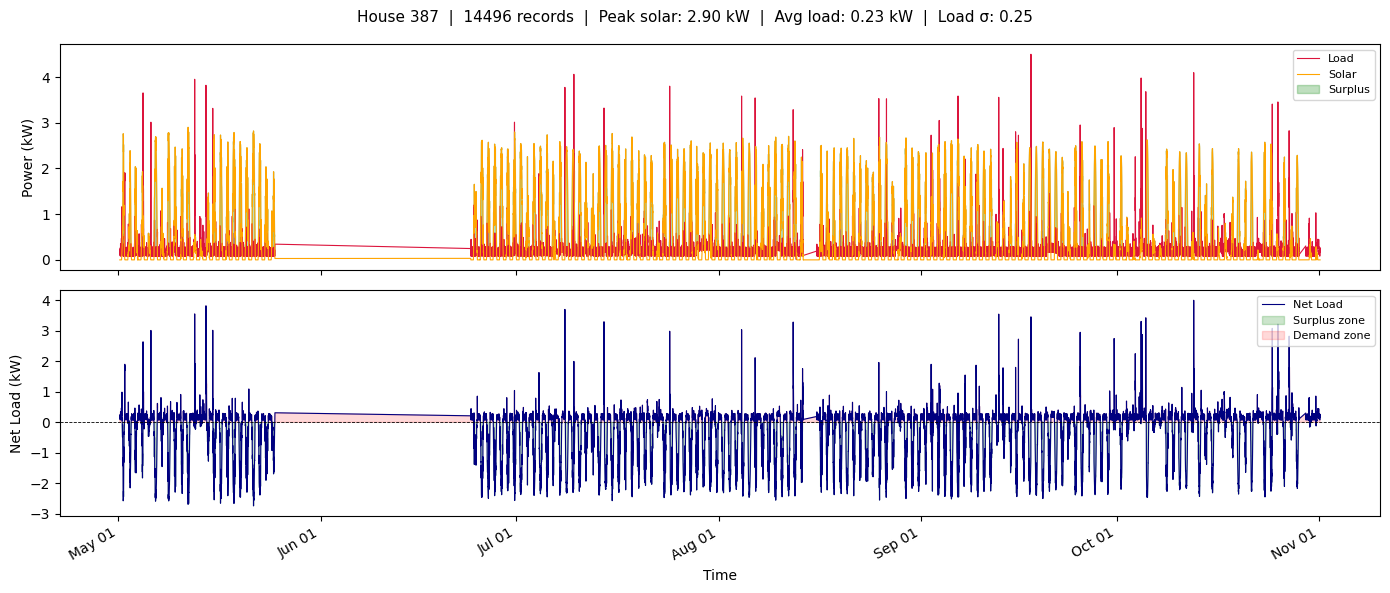

----------------------------------------------------------------------


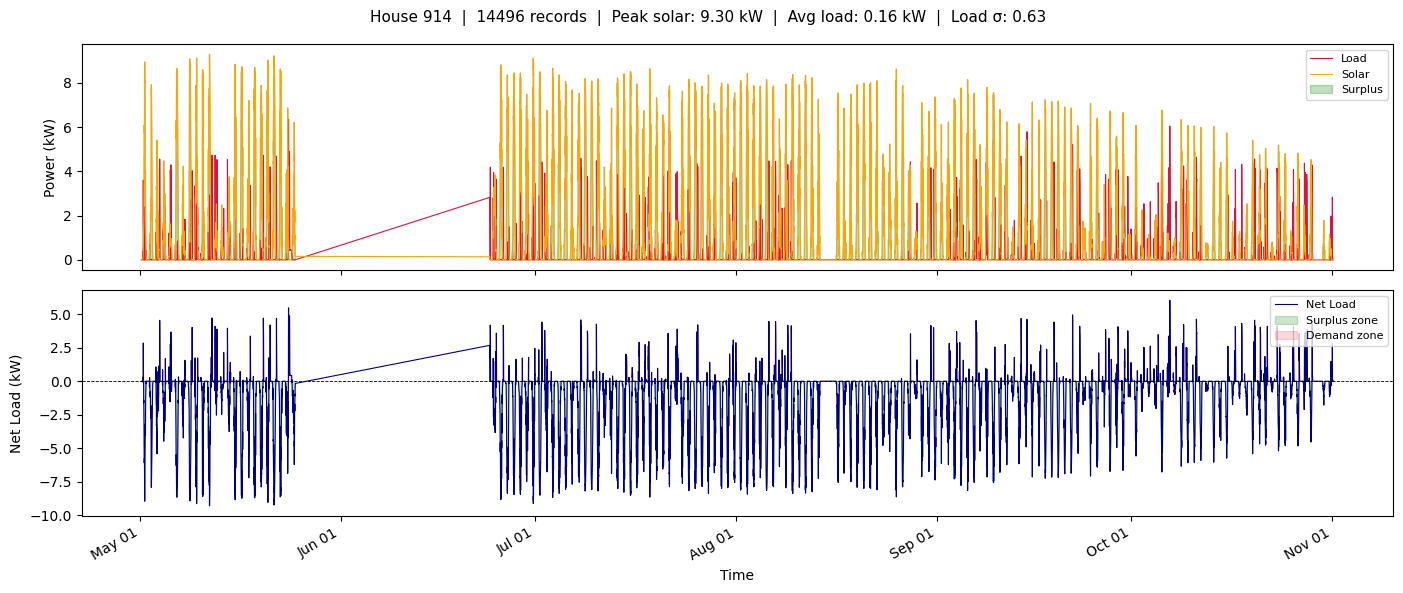

----------------------------------------------------------------------


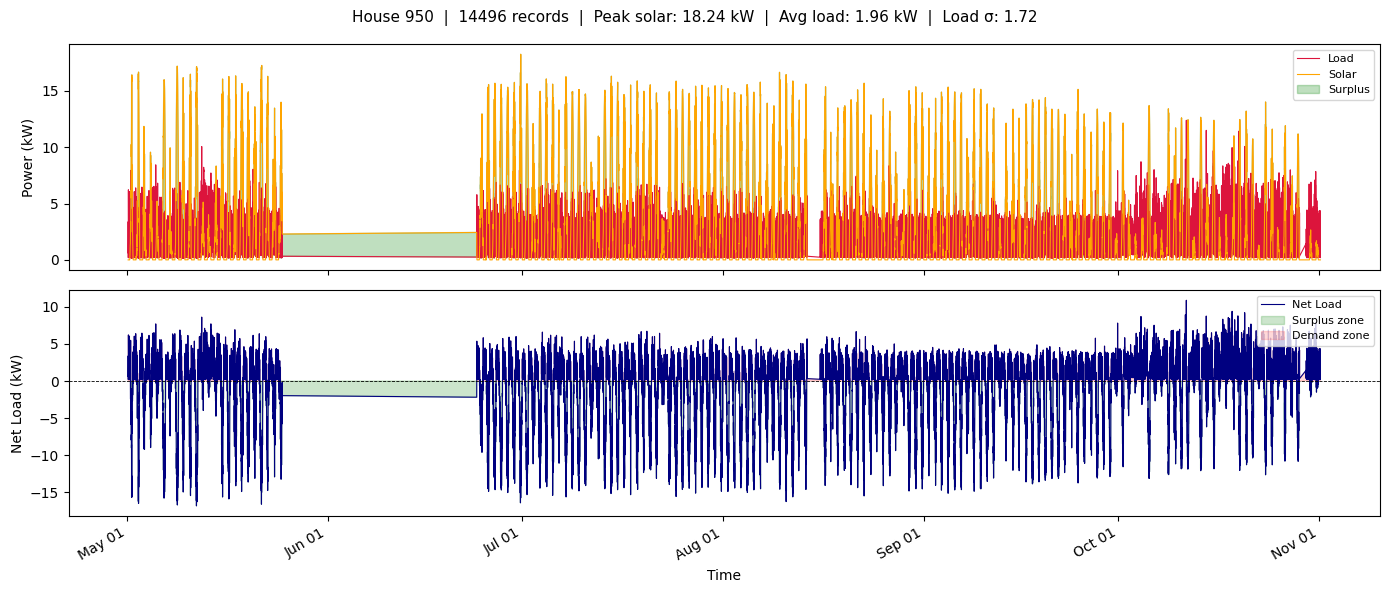

----------------------------------------------------------------------


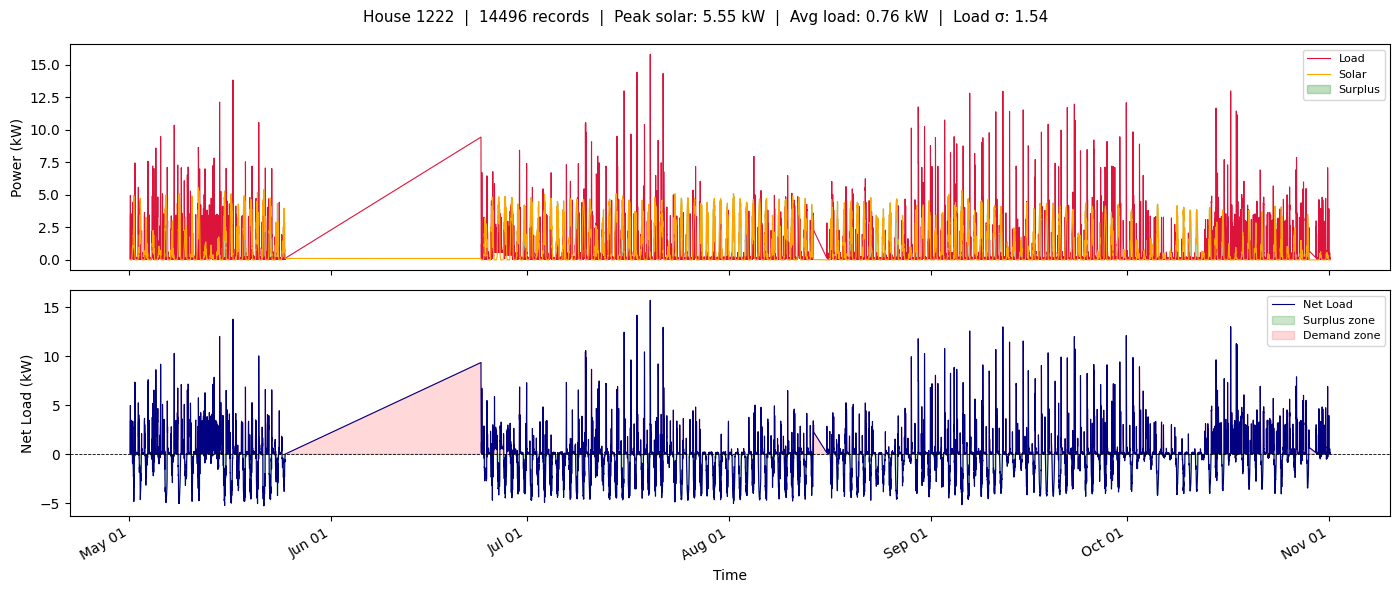

----------------------------------------------------------------------


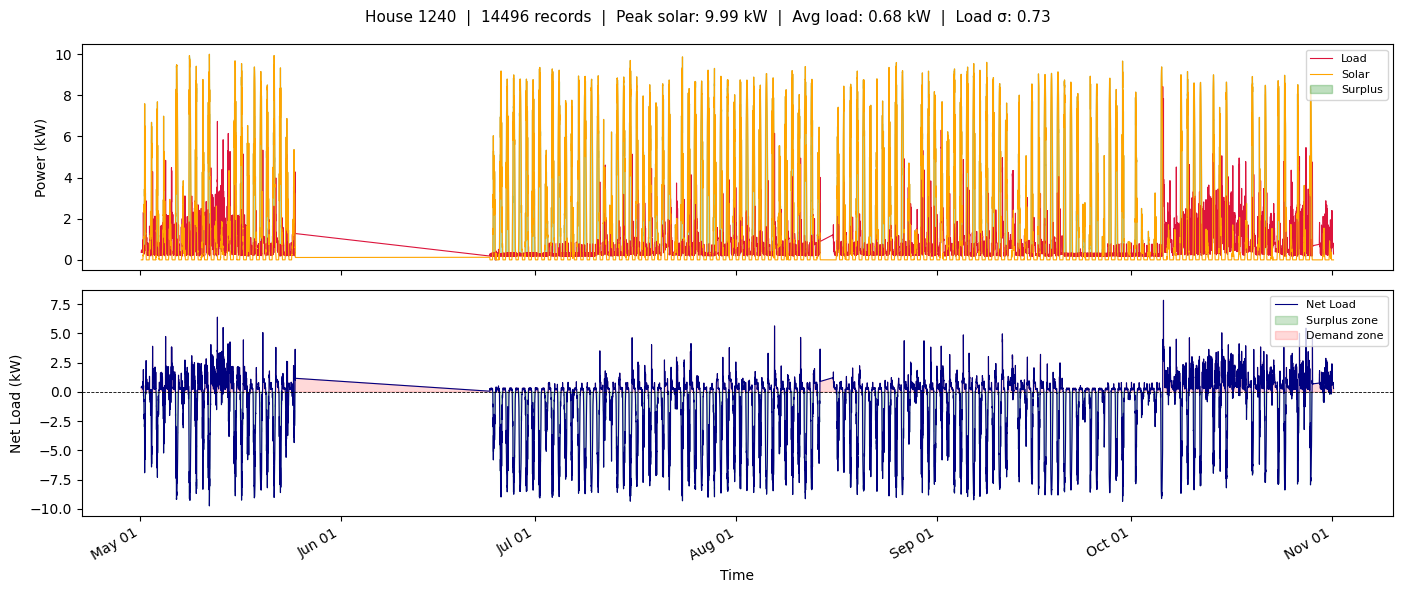

----------------------------------------------------------------------


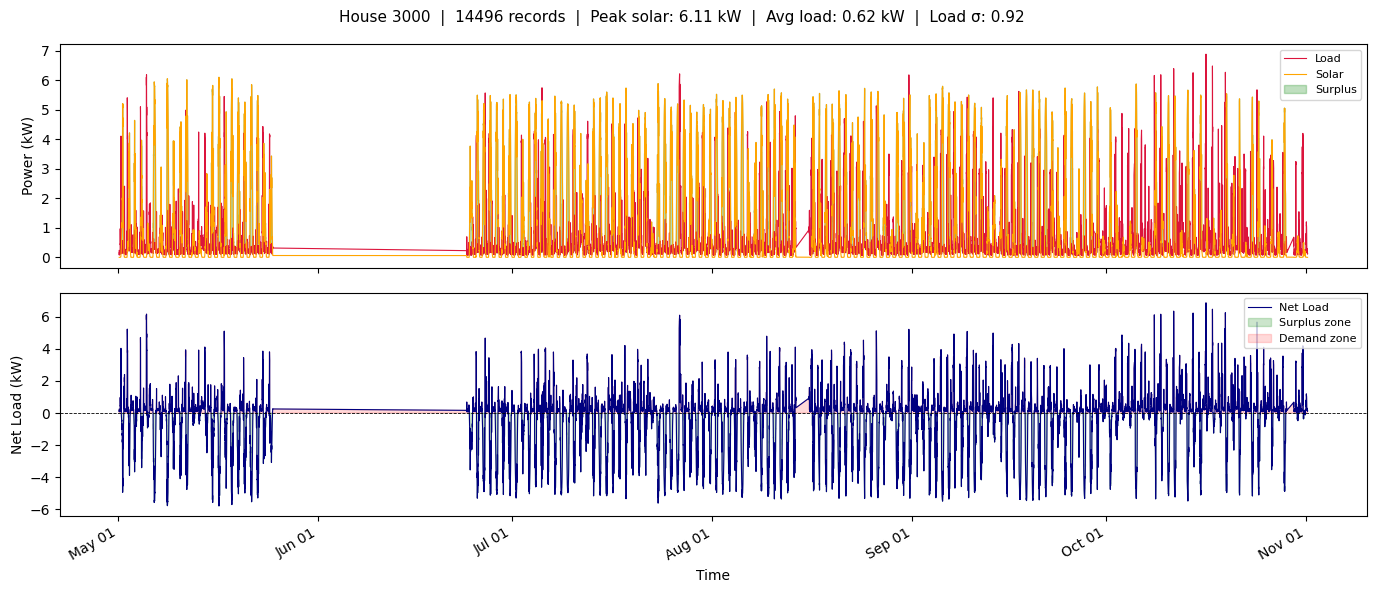

----------------------------------------------------------------------


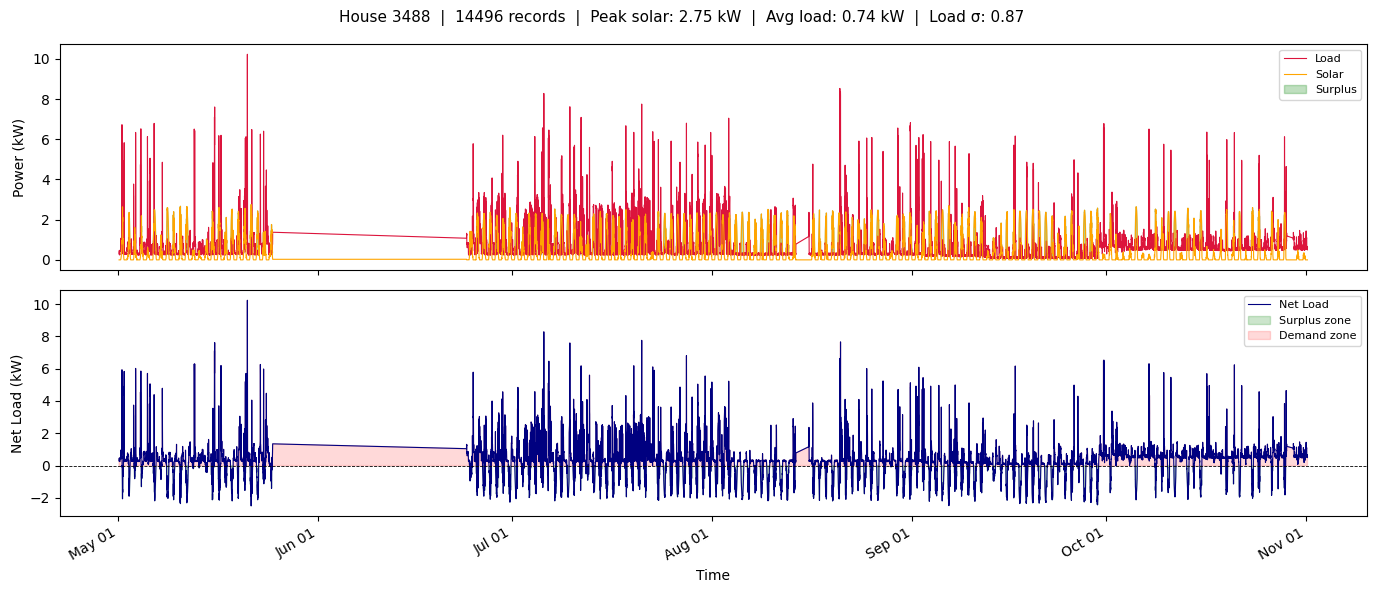

----------------------------------------------------------------------


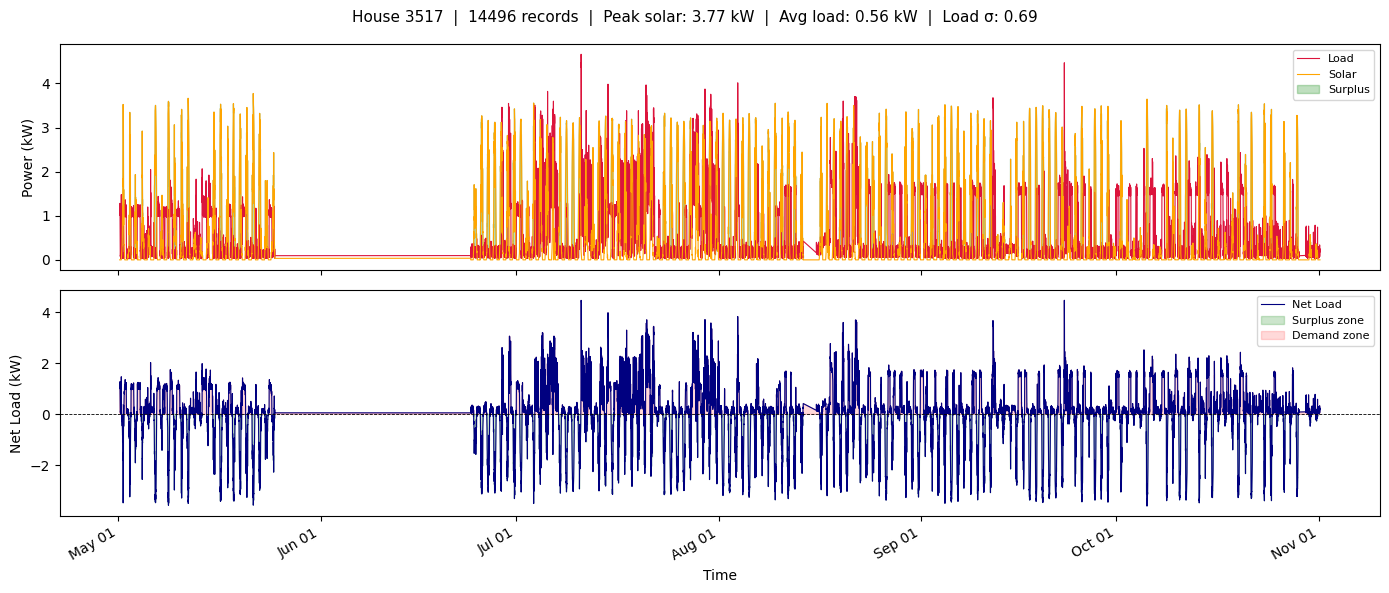

----------------------------------------------------------------------


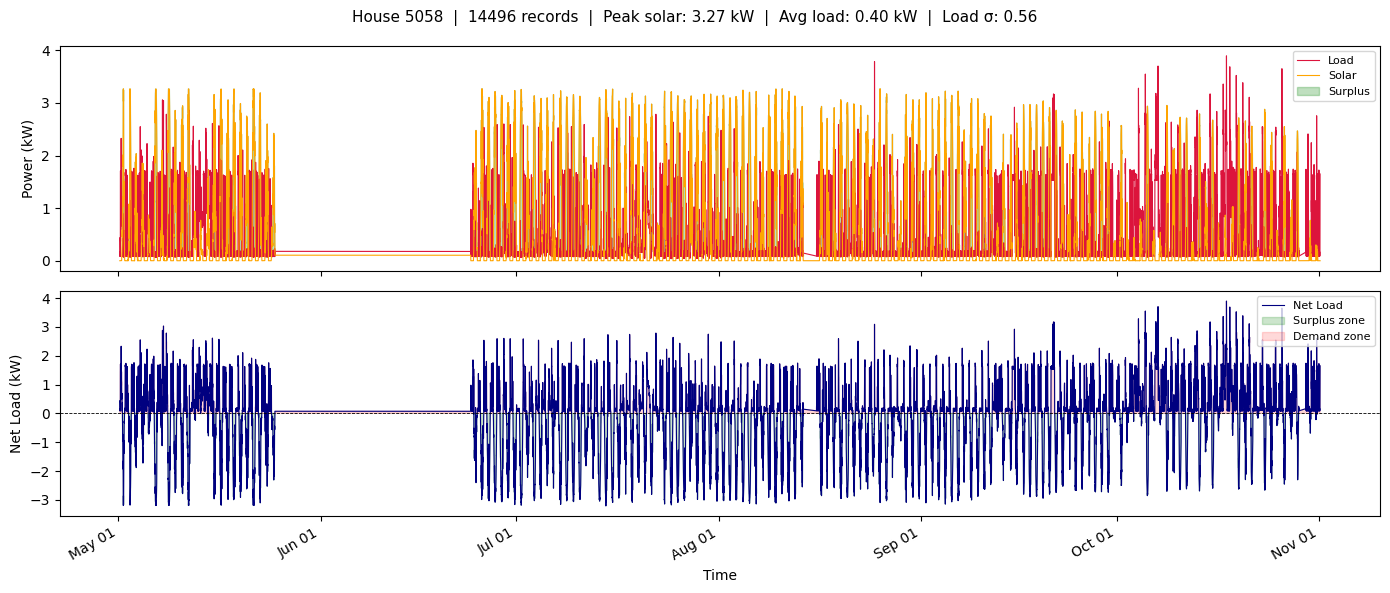

----------------------------------------------------------------------


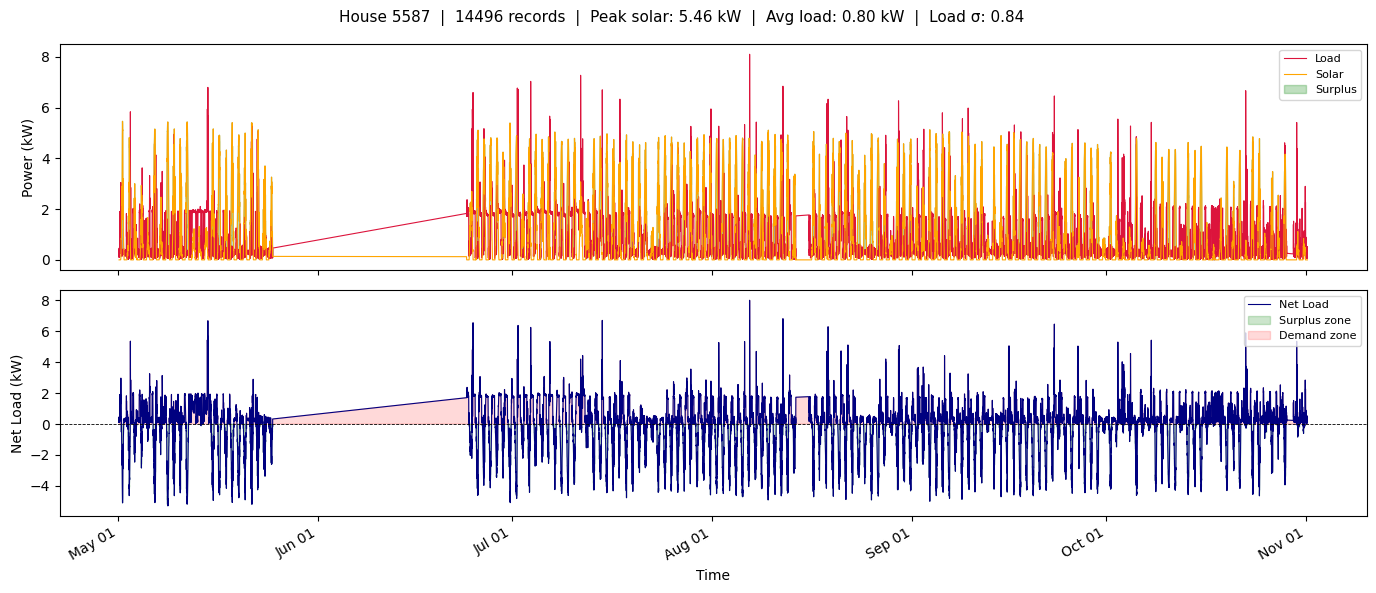

----------------------------------------------------------------------


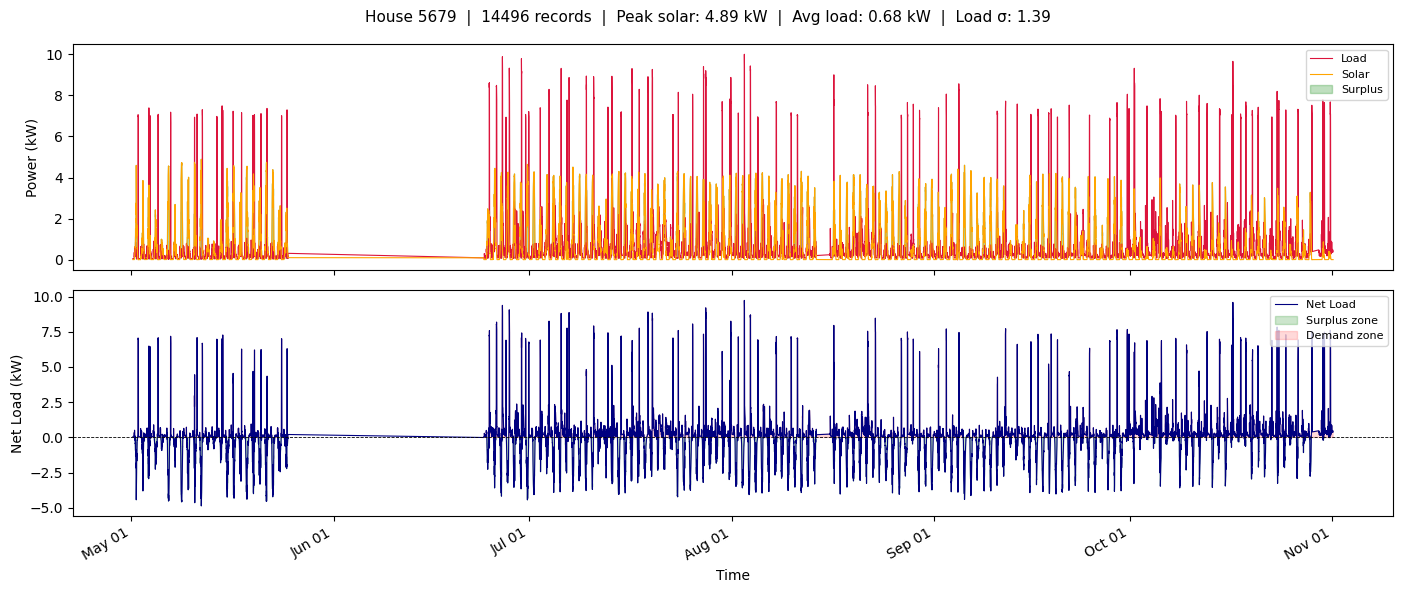

----------------------------------------------------------------------


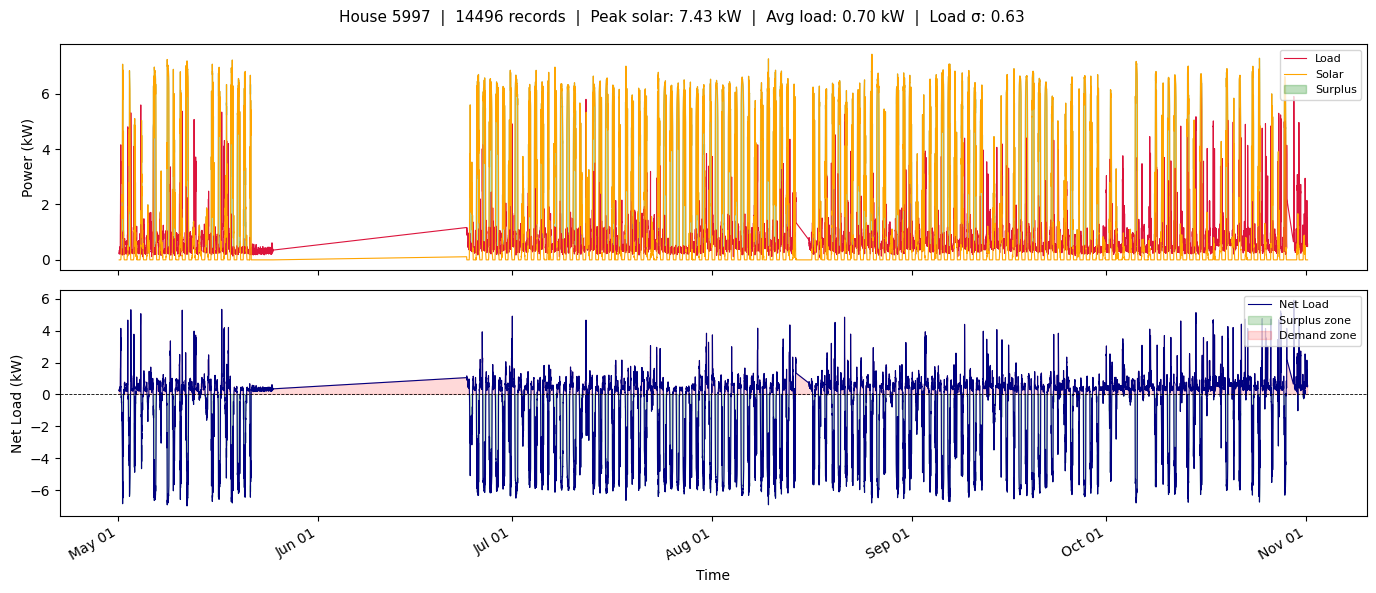

----------------------------------------------------------------------


In [ ]:
for hid in good_houses:
    h = df[df['dataid'] == hid].copy()

    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    fig.suptitle(f'House {hid}  |  {len(h)} records  |  '
                 f'Peak solar: {h["total_solar"].max():.2f} kW  |  '
                 f'Avg load: {h["total_load"].mean():.2f} kW  |  '
                 f'Load σ: {h["total_load"].std():.2f}',
                 fontsize=11)

    # Top: Load vs Solar
    ax = axes[0]
    ax.plot(h['local_15min'], h['total_load'],  color='crimson',  lw=0.8, label='Load')
    ax.plot(h['local_15min'], h['total_solar'], color='orange',   lw=0.8, label='Solar')
    ax.fill_between(h['local_15min'], h['total_load'], h['total_solar'],
                    where=(h['total_solar'] > h['total_load']),
                    color='green', alpha=0.25, label='Surplus')
    ax.set_ylabel('Power (kW)')
    ax.legend(loc='upper right', fontsize=8)

    # Bottom: Net Load
    ax2 = axes[1]
    ax2.plot(h['local_15min'], h['net_load'], color='navy', lw=0.8, label='Net Load')
    ax2.axhline(0, color='black', lw=0.6, linestyle='--')
    ax2.fill_between(h['local_15min'], h['net_load'], 0,
                     where=(h['net_load'] < 0), color='green', alpha=0.2, label='Surplus zone')
    ax2.fill_between(h['local_15min'], h['net_load'], 0,
                     where=(h['net_load'] > 0), color='red',   alpha=0.15, label='Demand zone')
    ax2.set_ylabel('Net Load (kW)')
    ax2.set_xlabel('Time')
    ax2.legend(loc='upper right', fontsize=8)

    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
    print('-' * 70)

In [ ]:
daily = df_raw.groupby(df_raw['local_15min'].dt.date)['dataid'].count()
print(daily[daily < daily.median() * 0.5])

local_15min
2019-11-01    500
Name: dataid, dtype: int64


In [ ]:
# Confirm bad_dates filter isn't touching October/November
print(df_raw['local_15min'].dt.month.value_counts().sort_index())

local_15min
5     57100
6     16800
7     74399
8     69600
9     72000
10    72000
11      500
Name: count, dtype: int64


## 8. Personality classification — who's Donor / Average / Spiky

In [ ]:
personality = []
for hid in good_houses:
    h = df[df['dataid'] == hid]
    avg_net   = h['net_load'].mean()
    volatility= h['total_load'].std()
    surplus_pct = (h['net_load'] < 0).mean() * 100

    personality.append({
        'dataid'        : hid,
        'avg_net_load'  : round(avg_net, 3),
        'load_volatility': round(volatility, 3),
        'surplus_pct'   : round(surplus_pct, 1),
        'peak_solar'    : round(h['total_solar'].max(), 2),
        'records'       : len(h),
    })

personality_df = pd.DataFrame(personality).set_index('dataid')

# Auto-label by percentile
vol_33  = personality_df['load_volatility'].quantile(0.33)
vol_66  = personality_df['load_volatility'].quantile(0.66)
net_med = personality_df['avg_net_load'].median()

def label(row):
    if row['surplus_pct'] > 40 and row['avg_net_load'] < net_med:
        return '🟢 DONOR (High Surplus)'
    elif row['load_volatility'] > vol_66:
        return '🔴 SPIKY (High Volatility)'
    else:
        return '🟡 BALANCED'

personality_df['type'] = personality_df.apply(label, axis=1)
print('=== HOUSE PERSONALITY CLASSIFICATION ===')
print(personality_df[['type','avg_net_load','load_volatility','surplus_pct','peak_solar','records']].to_string())

=== HOUSE PERSONALITY CLASSIFICATION ===
                             type  avg_net_load  load_volatility  surplus_pct  peak_solar  records
dataid                                                                                            
27         🟢 DONOR (High Surplus)        -1.175            0.966         41.2       11.62    14495
142                    🟡 BALANCED        -0.477            0.289         38.2        5.03    14496
387                    🟡 BALANCED        -0.297            0.246         39.3        2.90    14496
914        🟢 DONOR (High Surplus)        -1.139            0.627         49.0        9.30    14496
950     🔴 SPIKY (High Volatility)        -1.100            1.720         38.6       18.24    14496
1222    🔴 SPIKY (High Volatility)        -0.165            1.539         39.3        5.55    14496
1240       🟢 DONOR (High Surplus)        -1.048            0.728         40.2        9.99    14496
3000    🔴 SPIKY (High Volatility)        -0.407            0.921    

## 9. Pick 3 houses (one of each type) — manual override possible

In [ ]:
# Auto-select one DONOR, one BALANCED, one SPIKY house from available data
available = list(personality_df.index)

if len(available) < 3:
    raise ValueError(f'Need at least 3 houses after filtering; found {len(available)}')

def pick_house(mask, fallback_list):
    ids = personality_df[mask].index.tolist()
    if len(ids) > 0:
        return ids[0]
    return fallback_list[0]

donor_id = pick_house(
    (personality_df['surplus_pct'] > 40) &
    (personality_df['avg_net_load'] < personality_df['avg_net_load'].median()),
    available
)

balanced_candidates = [x for x in available if x != donor_id]
balanced_id = pick_house(
    (personality_df['load_volatility'] <= personality_df['load_volatility'].quantile(0.66)) &
    (personality_df.index != donor_id),
    balanced_candidates if balanced_candidates else available
)

spiky_candidates = [x for x in available if x not in {donor_id, balanced_id}]
spiky_id = pick_house(
    (personality_df['load_volatility'] >= personality_df['load_volatility'].quantile(0.66)) &
    (~personality_df.index.isin([donor_id, balanced_id])),
    spiky_candidates if spiky_candidates else available
)

# Ensure distinct IDs
chosen = []
for hid in [donor_id, balanced_id, spiky_id]:
    if hid not in chosen:
        chosen.append(hid)
for hid in available:
    if len(chosen) == 3:
        break
    if hid not in chosen:
        chosen.append(hid)

selected = {
    chosen[0]: 'DONOR',
    chosen[1]: 'BALANCED',
    chosen[2]: 'SPIKY',
}

print('=== SELECTED HOUSES (auto-selected) ===')
for hid, role in selected.items():
    row = personality_df.loc[hid]
    print(f"{role:10s}  ->  House {hid}  |  {row['records']} records  |  volatility={row['load_volatility']:.3f}  surplus={row['surplus_pct']}%")

=== SELECTED HOUSES (auto-selected) ===
DONOR       ->  House 27  |  14495 records  |  volatility=0.966  surplus=41.2%
BALANCED    ->  House 142  |  14496 records  |  volatility=0.289  surplus=38.2%
SPIKY       ->  House 950  |  14496 records  |  volatility=1.720  surplus=38.6%


## 10. Clean & gap-fill each selected house

In [ ]:
def clean_house(df_all, house_id, interval_min=15):
    """
    1. Slice house data
    2. Reindex to a perfect 15-min grid (no holes)
    3. Fill small gaps (≤ 1 hr = 4 steps) with linear interpolation
    4. Fill remaining gaps with forward-fill then backward-fill
    5. Report how many points were filled
    """
    h = df_all[df_all['dataid'] == house_id][['local_15min','total_load','total_solar','net_load']].copy()
    h = h.drop_duplicates('local_15min').set_index('local_15min').sort_index()

    # Perfect grid
    full_index = pd.date_range(h.index.min(), h.index.max(), freq=f'{interval_min}min')
    h = h.reindex(full_index)

    missing_before = h['net_load'].isna().sum()

    # Interpolate small gaps
    h = h.interpolate(method='linear', limit=4)
    # Fill any remaining with ffill/bfill
    h = h.ffill().bfill()

    missing_after = h['net_load'].isna().sum()

    h.index.name = 'timestamp'
    h['dataid']   = house_id

    # Solar must be non-negative
    h['total_solar'] = h['total_solar'].clip(lower=0)
    h['total_load']  = h['total_load'].clip(lower=0)
    h['net_load']    = h['total_load'] - h['total_solar']

    print(f'House {house_id}: {len(full_index)} total intervals | '
          f'gaps filled: {missing_before} | still missing: {missing_after}')
    return h

house_clean = {}
for hid in selected:
    house_clean[hid] = clean_house(df, hid)

print('\n✅ All selected houses cleaned')

House 27: 17664 total intervals | gaps filled: 3169 | still missing: 0
House 142: 17664 total intervals | gaps filled: 3168 | still missing: 0
House 950: 17664 total intervals | gaps filled: 3168 | still missing: 0

✅ All selected houses cleaned


## 11. Add time features (will be used by the CNN later)

In [ ]:
def add_time_features(h):
    h = h.copy()
    h['hour']        = h.index.hour
    h['minute']      = h.index.minute
    h['dayofweek']   = h.index.dayofweek          # 0=Mon … 6=Sun
    h['is_weekend']  = (h['dayofweek'] >= 5).astype(int)
    h['month']       = h.index.month
    # Cyclical encoding — so hour 23 and hour 0 are close
    h['hour_sin']    = np.sin(2 * np.pi * h['hour'] / 24)
    h['hour_cos']    = np.cos(2 * np.pi * h['hour'] / 24)
    h['dow_sin']     = np.sin(2 * np.pi * h['dayofweek'] / 7)
    h['dow_cos']     = np.cos(2 * np.pi * h['dayofweek'] / 7)
    return h

for hid in selected:
    house_clean[hid] = add_time_features(house_clean[hid])

print('✅ Time features added')
house_clean[list(selected.keys())[0]].head(3)

✅ Time features added


## 12. Normalize — MinMax on net_load, total_load, total_solar

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scalers = {}   # save scalers — you NEED them later to inverse-transform predictions

TARGET_COLS = ['net_load', 'total_load', 'total_solar']

for hid in selected:
    h = house_clean[hid].copy()

    # Fit scaler on net_load only (this is your prediction target)
    scaler_net = MinMaxScaler(feature_range=(-1, 1))  # (-1,1) handles negative net load properly
    h['net_load_scaled'] = scaler_net.fit_transform(h[['net_load']])

    # Separate 0-1 scalers for load & solar (always positive)
    scaler_load = MinMaxScaler()
    h['load_scaled']  = scaler_load.fit_transform(h[['total_load']])

    scaler_solar = MinMaxScaler()
    h['solar_scaled'] = scaler_solar.fit_transform(h[['total_solar']])

    scalers[hid] = {
        'net_load' : scaler_net,
        'load'     : scaler_load,
        'solar'    : scaler_solar,
    }
    house_clean[hid] = h

    print(f'House {hid} — net_load_scaled range: '
          f'[{h["net_load_scaled"].min():.3f}, {h["net_load_scaled"].max():.3f}]')

print('\n✅ Normalization done. Scalers saved in `scalers` dict.')

House 27 — net_load_scaled range: [-1.000, 1.000]
House 142 — net_load_scaled range: [-1.000, 1.000]
House 950 — net_load_scaled range: [-1.000, 1.000]

✅ Normalization done. Scalers saved in `scalers` dict.


## 13. Train / Calibration / Test split (70 / 15 / 15)

In [ ]:
splits = {}

for hid in selected:
    h = house_clean[hid].copy().reset_index()
    n = len(h)
    i1 = int(n * 0.70)
    i2 = int(n * 0.85)

    splits[hid] = {
        'train' : h.iloc[:i1],
        'calib' : h.iloc[i1:i2],   # ← ONLY for computing q_hat in conformal prediction
        'test'  : h.iloc[i2:],     # ← ONLY for reporting final metrics (never touch during training)
    }

    print(f'House {hid}  →  '
          f'train: {i1} | calib: {i2-i1} | test: {n-i2} | total: {n}')

print('\n✅ Splits created. Test set is locked — do not use until final evaluation.')

House 27  →  train: 12364 | calib: 2650 | test: 2650 | total: 17664
House 142  →  train: 12364 | calib: 2650 | test: 2650 | total: 17664
House 950  →  train: 12364 | calib: 2650 | test: 2650 | total: 17664

✅ Splits created. Test set is locked — do not use until final evaluation.


## 14. Final overview plot — normalized net_load for all 3 houses

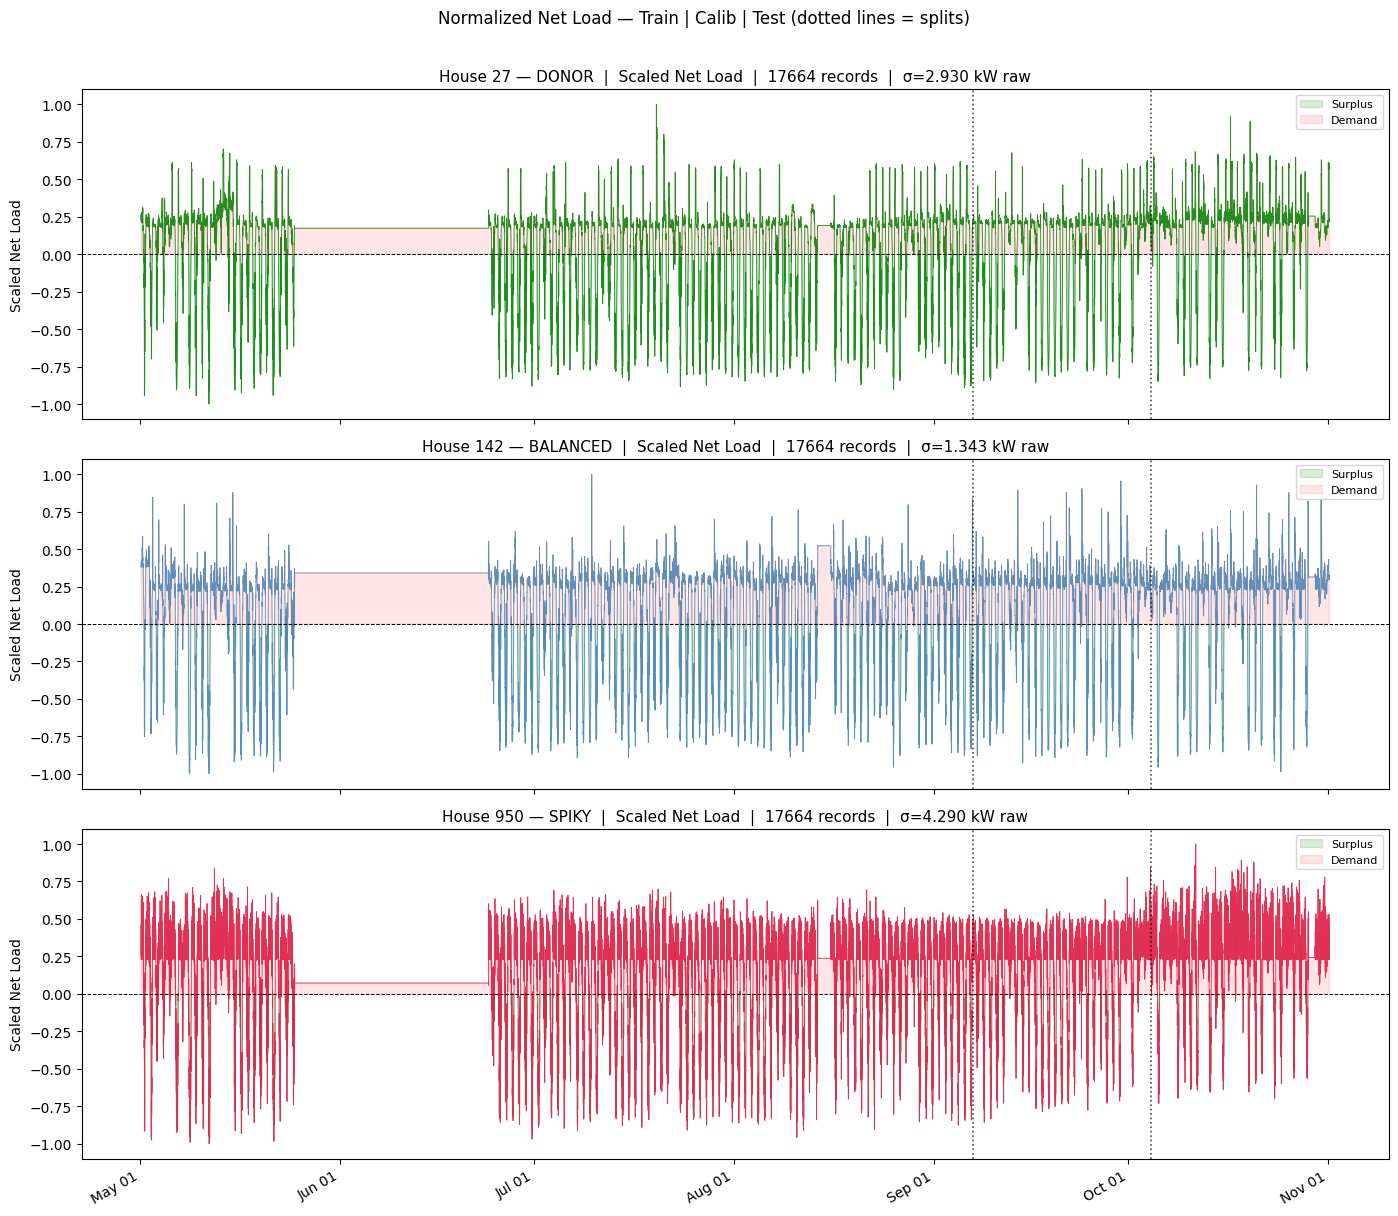

In [ ]:
colors = {'DONOR': 'green', 'BALANCED': 'steelblue', 'SPIKY': 'crimson'}

fig, axes = plt.subplots(len(selected), 1, figsize=(14, 4 * len(selected)), sharex=False)
if len(selected) == 1:
    axes = [axes]

for ax, (hid, role) in zip(axes, selected.items()):
    h = house_clean[hid]
    ax.plot(h.index, h['net_load_scaled'], lw=0.6, color=colors.get(role, 'navy'), alpha=0.85)
    ax.axhline(0, color='black', lw=0.7, linestyle='--')
    ax.fill_between(h.index, h['net_load_scaled'], 0,
                    where=(h['net_load_scaled'] < 0), color='green', alpha=0.15, label='Surplus')
    ax.fill_between(h.index, h['net_load_scaled'], 0,
                    where=(h['net_load_scaled'] > 0), color='red',   alpha=0.10, label='Demand')

    # Mark split boundaries
    split_dates = [
        splits[hid]['calib']['timestamp'].iloc[0],
        splits[hid]['test']['timestamp'].iloc[0],
    ]
    for sd in split_dates:
        ax.axvline(sd, color='black', lw=1.2, linestyle=':', alpha=0.7)

    ax.set_title(f'House {hid} — {role}  |  Scaled Net Load  |  '
                 f'{len(h)} records  |  '
                 f'σ={h["net_load"].std():.3f} kW raw', fontsize=11)
    ax.set_ylabel('Scaled Net Load')
    ax.legend(loc='upper right', fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    fig.autofmt_xdate()

plt.suptitle('Normalized Net Load — Train | Calib | Test (dotted lines = splits)', y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

## 15. Summary table — ready for model training

In [ ]:
rows = []
for hid, role in selected.items():
    h = house_clean[hid]
    rows.append({
        'House'           : hid,
        'Role'            : role,
        'Total Records'   : len(h),
        'Days of Data'    : (h.index.max() - h.index.min()).days,
        'Train samples'   : len(splits[hid]['train']),
        'Calib samples'   : len(splits[hid]['calib']),
        'Test samples'    : len(splits[hid]['test']),
        'Net Load σ (raw)': round(h['net_load'].std(), 3),
        'Surplus % time'  : round((h['net_load'] < 0).mean() * 100, 1),
        'Peak Solar (kW)' : round(h['total_solar'].max(), 2),
    })

summary = pd.DataFrame(rows).set_index('House')
print('=== FINAL PREPROCESSING SUMMARY ===')
print(summary.to_string())
print()
print('Variables ready for next stage:')
print('  house_clean  — dict of cleaned+normalized DataFrames per house')
print('  splits       — dict with train/calib/test per house')
print('  scalers      — dict with net_load/load/solar scalers per house')
print('  selected     — {house_id: role} mapping')

=== FINAL PREPROCESSING SUMMARY ===
           Role  Total Records  Days of Data  Train samples  Calib samples  Test samples  Net Load σ (raw)  Surplus % time  Peak Solar (kW)
House                                                                                                                                      
27        DONOR          17664           183          12364           2650          2650             2.930            33.8            11.62
142    BALANCED          17664           183          12364           2650          2650             1.343            31.4             5.03
950       SPIKY          17664           183          12364           2650          2650             4.290            48.0            18.24

Variables ready for next stage:
  house_clean  — dict of cleaned+normalized DataFrames per house
  splits       — dict with train/calib/test per house
  scalers      — dict with net_load/load/solar scalers per house
  selected     — {house_id: role} mapping


In [ ]:
daily = df_raw.groupby(df_raw['local_15min'].dt.date)['dataid'].count()
print(daily[daily < daily.median() * 0.5])

local_15min
2019-11-01    500
Name: dataid, dtype: int64


In [ ]:
import numpy as np

def create_windows(data_scaled, time_features, window_size=16):
    """
    data_scaled   : net_load_scaled column (the target)
    time_features : hour_sin, hour_cos, dow_sin, dow_cos, is_weekend columns
    window_size   : 16 steps = 4 hours lookback
    """
    X, y = [], []
    feat_array = time_features.values
    for i in range(len(data_scaled) - window_size):
        # Past 16 net_load values + time features at each step
        window_net = data_scaled[i : i + window_size].reshape(-1, 1)
        window_time = feat_array[i : i + window_size]          # shape (16, 5)
        X.append(np.hstack([window_net, window_time]))         # shape (16, 6)
        y.append(data_scaled[i + window_size])
    return np.array(X), np.array(y)

TIME_FEAT_COLS = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend']

windowed = {}
for hid in selected:
    for split_name in ['train', 'calib', 'test']:
        chunk = splits[hid][split_name]
        nl    = chunk['net_load_scaled'].values
        tf    = chunk[TIME_FEAT_COLS]
        X, y  = create_windows(nl, tf, window_size=16)
        windowed.setdefault(hid, {})[split_name] = (X, y)

    print(f"House {hid} → train: {windowed[hid]['train'][0].shape} | "
          f"calib: {windowed[hid]['calib'][0].shape} | "
          f"test: {windowed[hid]['test'][0].shape}")

House 27 → train: (12348, 16, 6) | calib: (2634, 16, 6) | test: (2634, 16, 6)
House 142 → train: (12348, 16, 6) | calib: (2634, 16, 6) | test: (2634, 16, 6)
House 950 → train: (12348, 16, 6) | calib: (2634, 16, 6) | test: (2634, 16, 6)


In [ ]:
# Persist critical preprocessing artifacts immediately (disconnect-safe)
with open(os.path.join(SAVE_DIR_ABLATION, 'selected.pkl'), 'wb') as f:
    pickle.dump(selected, f)
with open(os.path.join(SAVE_DIR_ABLATION, 'scalers.pkl'), 'wb') as f:
    pickle.dump(scalers, f)
with open(os.path.join(SAVE_DIR_ABLATION, 'windowed_all.pkl'), 'wb') as f:
    pickle.dump(windowed, f)

print('Saved preprocessing artifacts to:', SAVE_DIR_ABLATION)

Saved preprocessing artifacts to: /content/drive/MyDrive/microgrid_runs/run_20260406_174947/artifacts_ablation


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout, BatchNormalization

def build_model(input_shape):
    inp = Input(shape=input_shape)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(inp)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = LSTM(64, activation='tanh', return_sequences=False)(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation='relu')(x)
    out = Dense(1)(x)   # single point prediction
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

# input shape = (16 timesteps, 6 features)
sample_shape = windowed[list(selected.keys())[0]]['train'][0].shape[1:]
print(f'Input shape: {sample_shape}')

Input shape: (16, 6)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

models = {}
keras_ckpt_dir = os.path.join(RUN_DIR, 'keras_ckpts')
os.makedirs(keras_ckpt_dir, exist_ok=True)

for hid in selected:
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    print(f'\n=== Training House {hid} ({selected[hid]}) ===')
    X_train, y_train = windowed[hid]['train']

    # Fixed validation slice — no random shuffle
    n_val = int(len(X_train) * 0.1)
    X_tr, X_val = X_train[:-n_val], X_train[-n_val:]
    y_tr, y_val = y_train[:-n_val], y_train[-n_val:]

    model = build_model(X_train.shape[1:])
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True, monitor='val_loss'),
        ReduceLROnPlateau(patience=5, factor=0.5, monitor='val_loss'),
        ModelCheckpoint(
            filepath=os.path.join(keras_ckpt_dir, f'model_{hid}_best.keras'),
            monitor='val_loss',
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=os.path.join(keras_ckpt_dir, f'model_{hid}_last.keras'),
            monitor='val_loss',
            save_best_only=False,
            save_weights_only=False,
            verbose=0
        ),
    ]
    model.fit(X_tr, y_tr,
              validation_data=(X_val, y_val),
              epochs=100, batch_size=32,
              callbacks=callbacks, verbose=1)

    # Save final model into artifact directory too
    model.save(os.path.join(SAVE_DIR_ABLATION, f'model_{hid}.keras'))
    models[hid] = model
    print(f'House {hid} done; checkpoints written to {keras_ckpt_dir}')



=== Training House 27 (DONOR) ===
Epoch 1/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0311
Epoch 1: val_loss improved from None to 0.02746, saving model to /content/drive/MyDrive/microgrid_runs/run_20260406_174947/keras_ckpts/model_27_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/microgrid_runs/run_20260406_174947/keras_ckpts/model_27_best.keras
348/348 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0209 - val_loss: 0.0275 - learning_rate: 0.0010
Epoch 2/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0128
Epoch 2: val_loss improved from 0.02746 to 0.01575, saving model to /content/drive/MyDrive/microgrid_runs/run_20260406_174947/keras_ckpts/model_27_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/microgrid_runs/run_20260406_174947/keras_ckpts/model_27_best.keras
348/348 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0124 - val_loss: 0.0158 - learning_rate: 0.0010
Epoch 3/100
345/348 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.01

## Ablation: CQR removed
Quantile models and CQR calibration are skipped. The agent receives only point predictions and a fixed neutral uncertainty width of 1.0.

In [ ]:
# Check records around the cutoff area
daily = df_raw.groupby(df_raw['local_15min'].dt.date)['dataid'].count()
print(daily.tail(10))  # last 10 days
print()
print(f'Median daily records: {daily.median():.0f}')
print(f'Nov 1 records: {daily.get(pd.Timestamp("2019-11-01").date(), 0)}')

local_15min
2019-10-22    2400
2019-10-23    2400
2019-10-24    2400
2019-10-25    2400
2019-10-26    2400
2019-10-27    2400
2019-10-28    2400
2019-10-30    2400
2019-10-31    2400
2019-11-01     500
Name: dataid, dtype: int64

Median daily records: 2400
Nov 1 records: 500


In [ ]:
# Confirm bad_dates filter isn't touching October/November
print(df_raw['local_15min'].dt.month.value_counts().sort_index())

local_15min
5     57100
6     16800
7     74399
8     69600
9     72000
10    72000
11      500
Name: count, dtype: int64


House 27 (DONOR)  R2=0.9222  MAE=0.0554


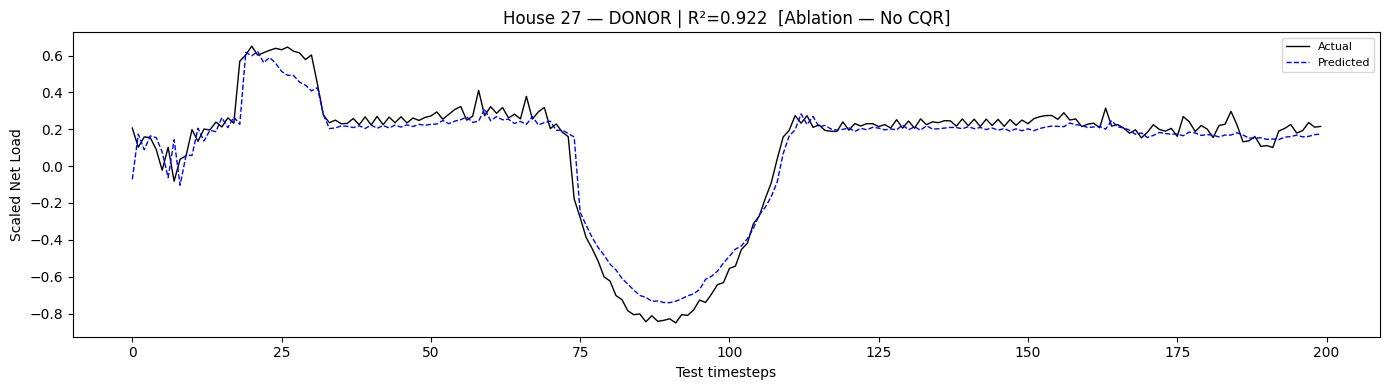

House 142 (BALANCED)  R2=0.9254  MAE=0.0503


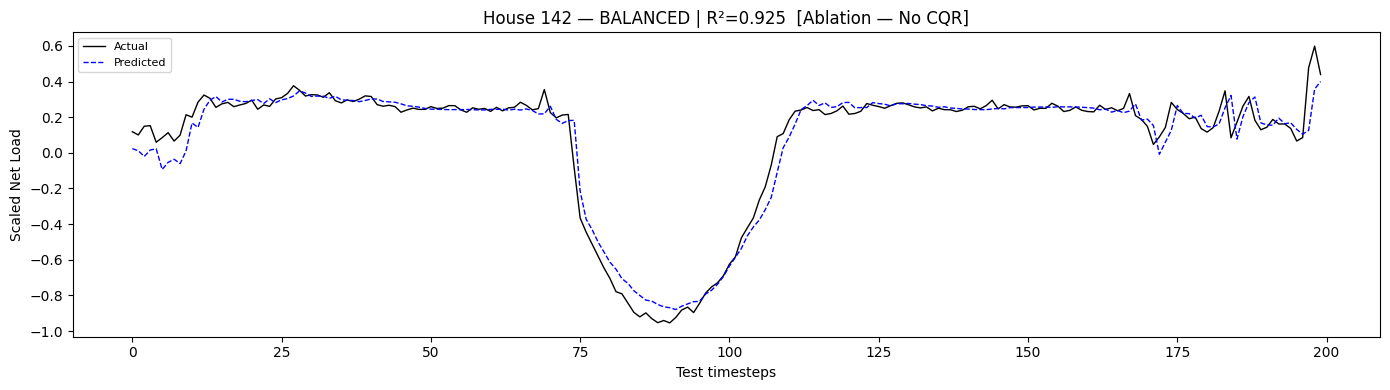

House 950 (SPIKY)  R2=0.7323  MAE=0.1089


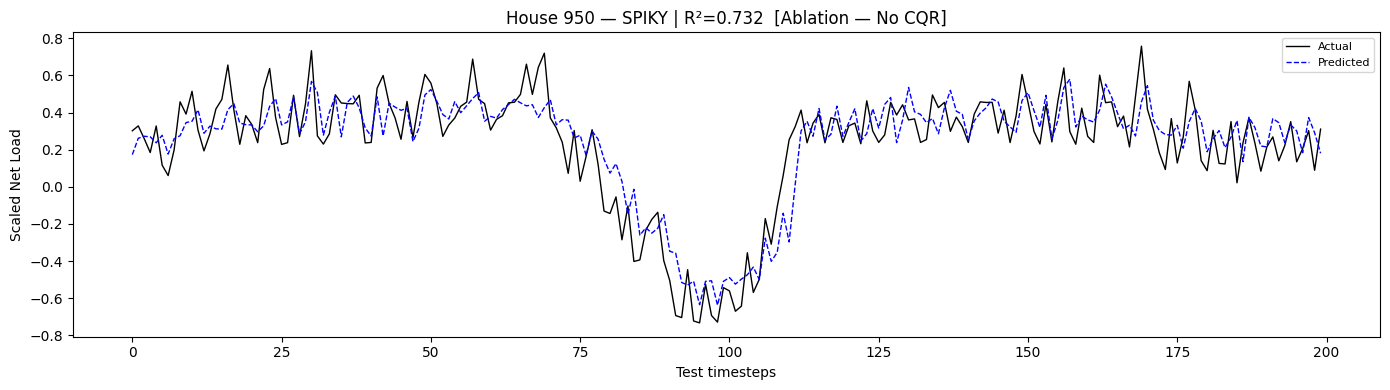

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

for hid in selected:
    X_test, y_test = windowed[hid]['test']
    y_pred = models[hid].predict(X_test, verbose=0).flatten()
    r2  = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    print(f'House {hid} ({selected[hid]})  R2={r2:.4f}  MAE={mae:.4f}')
    plt.figure(figsize=(14, 4))
    plt.plot(y_test[:200], color='black', lw=1, label='Actual')
    plt.plot(y_pred[:200], color='blue', lw=1, linestyle='--', label='Predicted')
    plt.title(f'House {hid} — {selected[hid]} | R²={r2:.3f}  [Ablation — No CQR]')
    plt.ylabel('Scaled Net Load'); plt.xlabel('Test timesteps')
    plt.legend(fontsize=8); plt.tight_layout(); plt.show()


In [ ]:
for hid in selected:
    X_train, y_train = windowed[hid]['train']
    X_test,  y_test  = windowed[hid]['test']

    train_pred = models[hid].predict(X_train, verbose=0).flatten()
    test_pred  = models[hid].predict(X_test,  verbose=0).flatten()

    r2_train = r2_score(y_train, train_pred)
    r2_test  = r2_score(y_test,  test_pred)
    gap      = r2_train - r2_test

    print(f'House {hid} ({selected[hid]})')
    print(f'  Train R²  : {r2_train:.4f}')
    print(f'  Test  R²  : {r2_test:.4f}')
    print(f'  Gap       : {gap:.4f}')

    if gap > 0.15:
        print(f'  ⚠️  OVERFITTING — gap too large')
    elif gap > 0.08:
        print(f'  🟡 MILD overfit — acceptable for research')
    else:
        print(f'  ✅ GOOD — model generalizes well')
    print()

House 27 (DONOR)
  Train R²  : 0.9272
  Test  R²  : 0.9222
  Gap       : 0.0050
  ✅ GOOD — model generalizes well

House 142 (BALANCED)
  Train R²  : 0.9348
  Test  R²  : 0.9254
  Gap       : 0.0094
  ✅ GOOD — model generalizes well

House 950 (SPIKY)
  Train R²  : 0.8753
  Test  R²  : 0.7323
  Gap       : 0.1429
  🟡 MILD overfit — acceptable for research



In [ ]:
import os, pickle, shutil
from google.colab import files

os.makedirs(SAVE_DIR_ABLATION, exist_ok=True)

for hid in selected:
    models[hid].save(f'{SAVE_DIR_ABLATION}/model_{hid}.keras')

with open(f'{SAVE_DIR_ABLATION}/scalers.pkl', 'wb') as f:
    pickle.dump(scalers, f)
with open(f'{SAVE_DIR_ABLATION}/selected.pkl', 'wb') as f:
    pickle.dump(selected, f)

windowed_save = {}
for hid in selected:
    windowed_save[hid] = {
        'train': windowed[hid]['train'],
        'calib': windowed[hid]['calib'],
        'test' : windowed[hid]['test'],
    }
with open(f'{SAVE_DIR_ABLATION}/windowed_all.pkl', 'wb') as f:
    pickle.dump(windowed_save, f)

print('Ablation models saved (no CQR):')
for fn in sorted(os.listdir(SAVE_DIR_ABLATION)):
    size = os.path.getsize(f'{SAVE_DIR_ABLATION}/{fn}') / 1024
    print(f'  {fn:40s} {size:.1f} KB')

zip_base = '/content/microgrid_saved_ablation'
shutil.make_archive(zip_base, 'zip', SAVE_DIR_ABLATION)
files.download(f'{zip_base}.zip')


Ablation models saved (no CQR):
  model_142.keras                          463.0 KB
  model_27.keras                           462.9 KB
  model_950.keras                          463.0 KB
  sac_agent_no_cqr_latest.zip              845.7 KB
  scalers.pkl                              2.8 KB
  selected.pkl                             0.0 KB
  windowed_all.pkl                         40049.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Optional emergency backup snapshot of the full run directory
backup_zip_base = os.path.join('/content', os.path.basename(RUN_DIR) + '_backup')
shutil.make_archive(backup_zip_base, 'zip', RUN_DIR)
backup_zip = backup_zip_base + '.zip'
print('Backup zip created:', backup_zip)
print(f'Backup size: {os.path.getsize(backup_zip)/1024/1024:.1f} MB')
# Uncomment next line if you want to download this snapshot manually:
# files.download(backup_zip)

Backup zip created: /content/run_20260406_174947_backup.zip
Backup size: 26.9 MB


In [ ]:
# Colab-safe package/bootstrap cell (idempotent)
import importlib

def _ensure_pkg(module_name, pip_name=None):
    try:
        importlib.import_module(module_name)
        return False
    except Exception:
        pkg = pip_name if pip_name is not None else module_name
        print(f'Installing {pkg} ...')
        get_ipython().run_line_magic('pip', f'install -q {pkg}')
        return True

installed_any = False
installed_any |= _ensure_pkg('stable_baselines3', 'stable-baselines3[extra]')
installed_any |= _ensure_pkg('gymnasium', 'gymnasium')

if installed_any:
    print('Packages installed in this runtime. If import errors persist, restart runtime and rerun from setup cell.')

import numpy as np
import pickle
import tensorflow as tf
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_checker import check_env
import matplotlib.pyplot as plt
import os

print('RL imports ready')

Installing stable-baselines3[extra] ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 23.7 MB/s eta 0:00:00
Packages installed in this runtime. If import errors persist, restart runtime and rerun from setup cell.
RL imports ready


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import numpy as np, pickle, tensorflow as tf

if not os.path.exists(SAVE_DIR_ABLATION):
    raise FileNotFoundError(f'SAVE_DIR_ABLATION not found: {SAVE_DIR_ABLATION}')

with open(f'{SAVE_DIR_ABLATION}/selected.pkl', 'rb') as f:
    selected = pickle.load(f)
with open(f'{SAVE_DIR_ABLATION}/scalers.pkl', 'rb') as f:
    scalers = pickle.load(f)
with open(f'{SAVE_DIR_ABLATION}/windowed_all.pkl', 'rb') as f:
    windowed_loaded = pickle.load(f)

models = {}
for hid in selected:
    models[hid] = tf.keras.models.load_model(f'{SAVE_DIR_ABLATION}/model_{hid}.keras')

house_ids_list = list(selected.keys())
windowed_all = {}
for hid in selected:
    X_all = np.concatenate([windowed_loaded[hid]['train'][0],
                             windowed_loaded[hid]['calib'][0],
                             windowed_loaded[hid]['test'][0]])
    y_all = np.concatenate([windowed_loaded[hid]['train'][1],
                             windowed_loaded[hid]['calib'][1],
                             windowed_loaded[hid]['test'][1]])
    windowed_all[hid] = {'all': (X_all, y_all)}

print('Ablation models loaded (no CQR)')
print(f'Houses: {selected}')
for hid in selected:
    X, y = windowed_all[hid]['all']
    print(f'House {hid} ({selected[hid]}) — total: {len(y)} | '
          f'surplus: {(y<-0.05).mean()*100:.1f}% | demand: {(y>0.05).mean()*100:.1f}%')


Ablation models loaded (no CQR)
Houses: {27: 'DONOR', 142: 'BALANCED', 950: 'SPIKY'}
House 27 (DONOR) — total: 17616 | surplus: 21.5% | demand: 75.2%
House 142 (BALANCED) — total: 17616 | surplus: 20.5% | demand: 76.4%
House 950 (SPIKY) — total: 17616 | surplus: 18.7% | demand: 77.7%


In [ ]:
import numpy as np, pickle

with open(f'{SAVE_DIR_ABLATION}/windowed_all.pkl', 'rb') as f:
    windowed_loaded = pickle.load(f)

windowed_all = {}
for hid in selected:
    X_all = np.concatenate([windowed_loaded[hid]['train'][0],
                             windowed_loaded[hid]['calib'][0],
                             windowed_loaded[hid]['test'][0]])
    y_all = np.concatenate([windowed_loaded[hid]['train'][1],
                             windowed_loaded[hid]['calib'][1],
                             windowed_loaded[hid]['test'][1]])
    windowed_all[hid] = {'all': (X_all, y_all)}

house_ids_list = list(selected.keys())
for hid in house_ids_list:
    y = windowed_all[hid]['all'][1]
    print(f'House {hid} ({selected[hid]}) — steps: {len(y)} | '
          f'surplus: {(y<-0.01).mean()*100:.1f}% | demand: {(y>0.01).mean()*100:.1f}%')
print('windowed_all ready')


House 27 (DONOR) — steps: 17616 | surplus: 22.6% | demand: 76.7%
House 142 (BALANCED) — steps: 17616 | surplus: 21.6% | demand: 77.8%
House 950 (SPIKY) — steps: 17616 | surplus: 20.1% | demand: 79.2%
windowed_all ready


In [ ]:
class BatterySimulator:
    def __init__(self, capacity=10.0):
        self.capacity = capacity
        self.min_soc  = 0.20
        self.max_soc  = 0.90
        self.soc      = 0.5

    def charge(self, amount_kw, dt=0.25):
        if amount_kw <= 0: return 0.0
        energy   = amount_kw * dt
        headroom = (self.max_soc - self.soc) * self.capacity
        actual   = min(energy, headroom)
        self.soc += actual / self.capacity
        return actual

    def discharge(self, amount_kw, dt=0.25):
        if amount_kw <= 0: return 0.0
        energy    = amount_kw * dt
        available = (self.soc - self.min_soc) * self.capacity
        actual    = min(energy, available)
        self.soc -= actual / self.capacity
        return actual

    def stress_penalty(self):
        if self.soc < 0.20 or self.soc > 0.90: return 2.0
        elif self.soc < 0.25 or self.soc > 0.85: return 1.0
        return 0.0

    def reset(self, seed_val=None):
        rng = np.random.default_rng(seed_val if seed_val is not None else SEED)
        self.soc = float(rng.uniform(0.4, 0.6))


In [ ]:
import gymnasium as gym
from gymnasium import spaces

class MicrogridGymEnv(gym.Env):
    """Ablation: SAC without CQR. Point predictions only, no uncertainty intervals."""
    metadata = {'render_modes': []}

    def __init__(self, house_ids, windowed_data, models_dict, split='all'):
        super().__init__()
        self.house_ids = house_ids
        self.n_houses  = len(house_ids)

        self.predictions = {}
        self.actuals     = {}

        for hid in house_ids:
            X, y   = windowed_data[hid][split]
            y_pred = models_dict[hid].predict(X, verbose=0).flatten()
            self.predictions[hid] = np.clip(y_pred, -2.0, 2.0)
            self.actuals[hid]     = y.flatten()

        self.total_steps = min(len(self.actuals[h]) for h in house_ids)
        self.episode_len = 96 * 7
        self.batteries   = {hid: BatterySimulator() for hid in house_ids}
        self.state_size  = self.n_houses * 3 + 2  # same shape as CQR version

        self.observation_space = spaces.Box(low=-3.0, high=3.0,
            shape=(self.state_size,), dtype=np.float32)
        self.action_space = spaces.Box(low=-1.0, high=1.0,
            shape=(self.n_houses,), dtype=np.float32)
        self.t = self.t_start = 0
        print(f'Ablation Env (No CQR) | Houses: {house_ids} | '
              f'Total steps: {self.total_steps} | Episode len: {self.episode_len}')

    def _get_obs(self):
        obs = []
        for hid in self.house_ids:
            obs.append(np.clip(float(self.predictions[hid][self.t]), -3.0, 3.0))
            obs.append(1.0)   # fixed neutral width — no CQR uncertainty
            obs.append(float(self.batteries[hid].soc))
        hour = self.t % 96
        obs.append(float(np.sin(2 * np.pi * hour / 96)))
        obs.append(float(np.cos(2 * np.pi * hour / 96)))
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        max_start    = self.total_steps - self.episode_len - 1
        self.t_start = int(np.random.randint(0, max(1, max_start)))
        self.t       = self.t_start
        for hid in self.house_ids:
            self.batteries[hid].reset()
        return self._get_obs(), {}

    def step(self, actions):
        actions = np.clip(actions, -1.0, 1.0)
        total_reward = grid_import = energy_shared = 0.0
        load_unmet = unsafe_trades = 0

        for i, hid in enumerate(self.house_ids):
            action     = float(actions[i])
            actual_net = float(self.actuals[hid][self.t])
            battery    = self.batteries[hid]
            reward     = 0.0
            has_surplus = actual_net < -0.01
            has_demand  = actual_net >  0.01

            if action < -0.33:
                if has_surplus:
                    share_kwh      = abs(actual_net) * abs(action) * 0.25
                    energy_shared += share_kwh
                    reward        += 1.0 * share_kwh
                    # No CQR risk penalty — ablation
                elif has_demand:
                    reward -= 0.8
                    unsafe_trades += 1  # sharing when you have demand = unsafe
                else:
                    reward -= 0.1
            elif action > 0.33:
                if has_demand:
                    grid_kwh     = actual_net * action * 0.25
                    grid_import += grid_kwh
                    reward      -= 1.2 * grid_kwh
                elif has_surplus:
                    reward -= 1.0
                    unsafe_trades += 1  # importing when you have surplus = unsafe
                else:
                    reward -= 0.2
            else:
                if has_surplus:
                    charged = battery.charge(abs(actual_net))
                    reward += 0.4 * charged
                elif has_demand:
                    provided  = battery.discharge(actual_net)
                    unmet_kwh = max(0.0, actual_net * 0.25 - provided)
                    if provided > 0:
                        reward += 0.6 * provided
                    if unmet_kwh > 0:
                        grid_import += unmet_kwh / 0.25
                        reward      -= 1.5 * unmet_kwh
                        load_unmet  += 1
                else:
                    reward += 0.01

            reward -= 0.3 * battery.stress_penalty()
            total_reward += reward

        total_reward /= self.n_houses
        self.t += 1
        done = (self.t >= self.t_start + self.episode_len) or (self.t >= self.total_steps - 1)
        obs  = np.zeros(self.state_size, dtype=np.float32) if done else self._get_obs()
        return obs, float(total_reward), done, False, {
            'grid_import': float(grid_import), 'energy_shared': float(energy_shared),
            'load_unmet': int(load_unmet), 'unsafe_trades': int(unsafe_trades)}


In [ ]:
from stable_baselines3.common.env_checker import check_env

env = MicrogridGymEnv(house_ids_list, windowed_all, models, split='all')
check_env(env, warn=True)
print('✅ Ablation Env passed checks')

obs, _ = env.reset()
total_r = shared = grid = 0
for _ in range(env.episode_len):
    action = env.action_space.sample()
    obs, r, done, _, info = env.step(action)
    total_r += r; shared += info['energy_shared']; grid += info['grid_import']
    if done: break
print(f'Random policy -> Reward: {total_r:.2f} | Shared: {shared:.4f} | Grid: {grid:.4f}')


Ablation Env (No CQR) | Houses: [27, 142, 950] | Total steps: 17616 | Episode len: 672
✅ Ablation Env passed checks
Random policy -> Reward: -190.14 | Shared: 16.1660 | Grid: 25.0405


In [ ]:
from stable_baselines3.common.callbacks import BaseCallback

class MetricsCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.episode_rewards  = []
        self.episode_grid     = []
        self.episode_shared   = []
        self.episode_lolp     = []
        self.episode_unsafe   = []
        self.episode_p2p_rate = []
        self._reset_ep()

    def _reset_ep(self):
        self._r = self._grid = self._shared = 0.0
        self._unmet = self._unsafe = self._steps = 0

    def _on_step(self):
        info = self.locals['infos'][0]
        self._r      += self.locals['rewards'][0]
        self._grid   += info.get('grid_import',   0)
        self._shared += info.get('energy_shared', 0)
        self._unmet  += info.get('load_unmet',    0)
        self._unsafe += info.get('unsafe_trades', 0)
        self._steps  += 1
        if self.locals['dones'][0]:
            self.episode_rewards.append(self._r)
            self.episode_grid.append(self._grid)
            self.episode_shared.append(self._shared)
            self.episode_lolp.append(self._unmet / max(self._steps,1) * 100)
            self.episode_unsafe.append(self._unsafe)
            self.episode_p2p_rate.append(
                self._shared / max(self._grid + self._shared, 1e-6) * 100)
            self._reset_ep()
        return True


In [ ]:
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import CheckpointCallback
import os
import glob
import torch as th

# ===== Free-Colab/Low-RAM profile =====
FREE_COLAB_PROFILE = True
TOTAL_TIMESTEPS_TARGET = 80_000
CHUNK_TIMESTEPS = 20_000

if FREE_COLAB_PROFILE:
    SAC_BUFFER_SIZE = 20_000
    SAC_BATCH_SIZE = 64
    SAC_NET_ARCH = [128, 128]
    SAC_SAVE_FREQ = 5_000
else:
    SAC_BUFFER_SIZE = 100_000
    SAC_BATCH_SIZE = 256
    SAC_NET_ARCH = [256, 256, 128]
    SAC_SAVE_FREQ = 10_000

env = MicrogridGymEnv(house_ids_list, windowed_all, models, split='all')

sac_ckpt_dir = os.path.join(RUN_DIR, 'sac_ckpts')
os.makedirs(sac_ckpt_dir, exist_ok=True)

# Pick a stable torch device. If CUDA kernels are broken, fallback to CPU.
sb3_device = 'cpu'
if th.cuda.is_available():
    try:
        _probe = th.randn(8, 8, device='cuda')
        _probe = _probe @ _probe.T
        th.cuda.synchronize()
        sb3_device = 'cuda'
    except Exception as e:
        print(f'CUDA probe failed, falling back to CPU: {e}')

print('SAC device:', sb3_device)
print('Training target timesteps:', TOTAL_TIMESTEPS_TARGET)
print('Chunk timesteps:', CHUNK_TIMESTEPS)

# Resume from latest checkpoint if available
existing_ckpts = sorted(glob.glob(os.path.join(sac_ckpt_dir, 'sac_agent_*_steps.zip')))
if existing_ckpts:
    latest_ckpt = existing_ckpts[-1]
    print('Resuming SAC from:', latest_ckpt)
    sac_agent = SAC.load(latest_ckpt, env=env, device=sb3_device)
    reset_steps = False
else:
    print('Starting fresh SAC training')
    sac_agent = SAC(
        policy='MlpPolicy', env=env, device=sb3_device,
        learning_rate=3e-4, buffer_size=SAC_BUFFER_SIZE, batch_size=SAC_BATCH_SIZE,
        learning_starts=2_000, train_freq=1, gradient_steps=1,
        gamma=0.99, tau=0.005, ent_coef=0.1,
        policy_kwargs=dict(net_arch=SAC_NET_ARCH),
        seed=SEED, verbose=1,
    )
    reset_steps = True

metrics_cb = MetricsCallback()
ckpt_cb = CheckpointCallback(
    save_freq=SAC_SAVE_FREQ,
    save_path=sac_ckpt_dir,
    name_prefix='sac_agent'
 )

# Train in chunks so Colab disconnects hurt less.
trained = 0
while trained < TOTAL_TIMESTEPS_TARGET:
    step_chunk = min(CHUNK_TIMESTEPS, TOTAL_TIMESTEPS_TARGET - trained)
    print(f'Learning chunk: {step_chunk} timesteps (done: {trained}/{TOTAL_TIMESTEPS_TARGET})')
    sac_agent.learn(
        total_timesteps=step_chunk,
        callback=[metrics_cb, ckpt_cb],
        reset_num_timesteps=reset_steps
    )
    trained += step_chunk
    reset_steps = False

    # Save a recoverable latest model after each chunk.
    latest_chunk_path = os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_latest')
    sac_agent.save(latest_chunk_path)
    print('Saved latest chunk model to:', latest_chunk_path)

final_sac_path = os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_final')
sac_agent.save(final_sac_path)
print('SAC (no CQR) training complete')
print('Final SAC saved to:', final_sac_path)
print('Checkpoint folder:', sac_ckpt_dir)


Ablation Env (No CQR) | Houses: [27, 142, 950] | Total steps: 17616 | Episode len: 672
SAC device: cuda
Training target timesteps: 80000
Chunk timesteps: 20000
Resuming SAC from: /content/drive/MyDrive/microgrid_runs/run_20260406_174947/sac_ckpts/sac_agent_75000_steps.zip
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Learning chunk: 20000 timesteps (done: 0/80000)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 672      |
|    ep_rew_mean     | -103     |
| time/              |          |
|    episodes        | 112      |
|    fps             | 79       |
|    time_elapsed    | 8        |
|    total_timesteps | 75672    |
| train/             |          |
|    actor_loss      | 10.3     |
|    critic_loss     | 0.319    |
|    ent_coef        | 0.1      |
|    learning_rate   | 0.0003   |
|    n_updates       | 73670    |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 672      |
|    ep_rew_mean     | -101     |
| time/              |          |
|    episodes        | 116      |
|    fps             | 89       |
|    time_elapsed    | 37       |
|    total_timesteps | 78360    |
| train/             |          |
|    actor_loss      | 11.1     |
|    critic_loss     | 0.162    |
|    ent_coef        | 0.1      |
|    learning_

Evaluation episode_len: 192


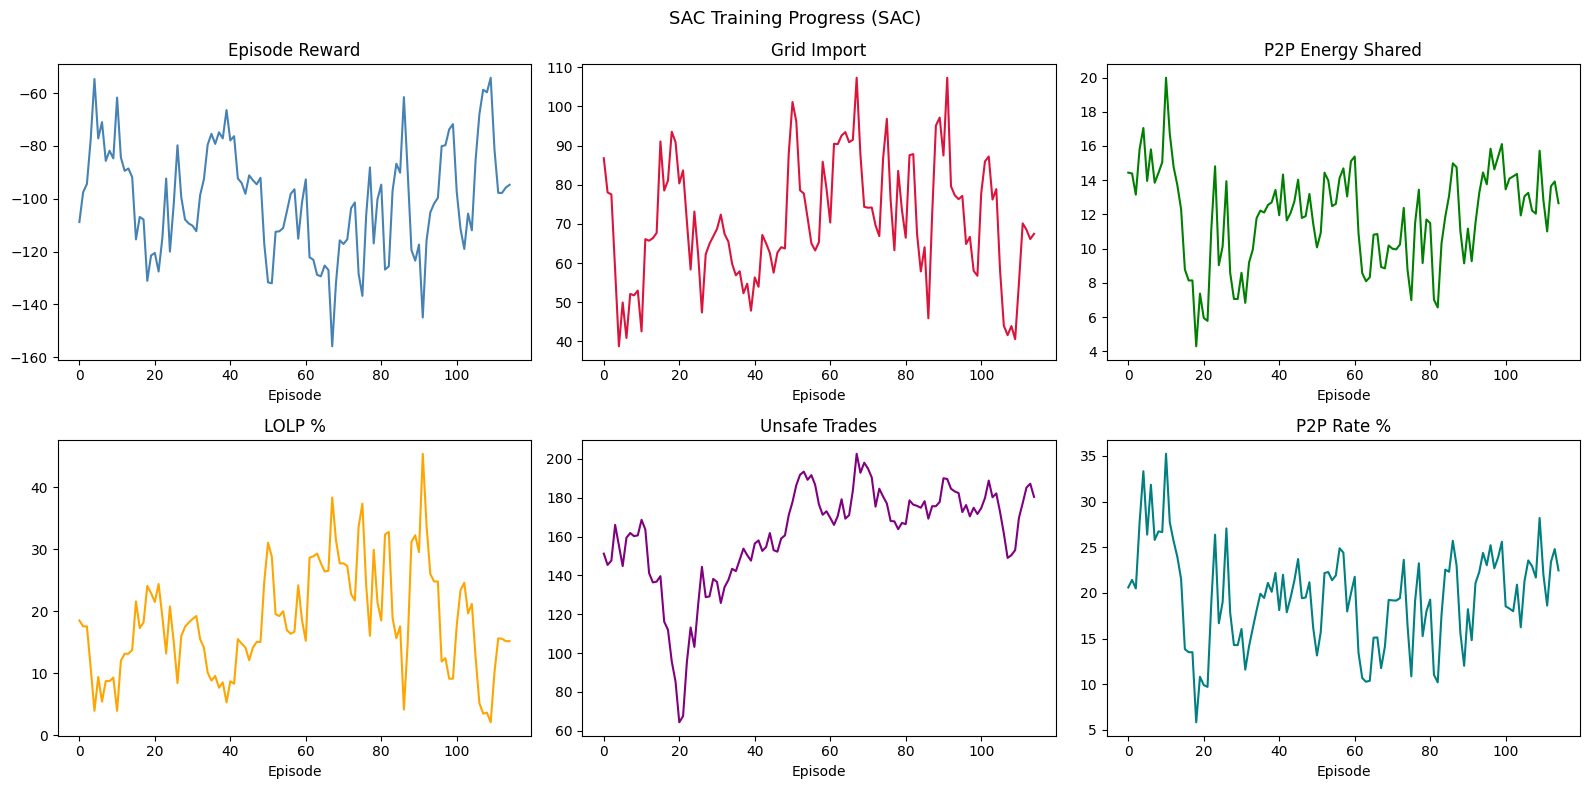


FINAL RESULTS (SAC)
Metric                   Baseline     Random        SAC
Grid Import                24.557     10.551     15.006
P2P Shared                  0.000      3.109      3.355
LOLP %                      0.000      8.854      0.000
Unsafe Trades               0.000    197.000      8.000
Grid Reduction: 38.9%
P2P Improvement: 335460286.7%


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch as th
from stable_baselines3 import SAC

# Fast eval mode for free Colab to avoid RAM/runtime blowups
FAST_EVAL_MODE = True
EVAL_EPISODE_LEN = 96 * 2 if FAST_EVAL_MODE else 96 * 7

def smooth(x, w=5):
    return np.convolve(x, np.ones(w) / w, mode='valid') if len(x) >= w else x

def _is_cuda_runtime_error(err: Exception) -> bool:
    msg = str(err).lower()
    cuda_markers = [
        'acceleratorerror',
        'cuda error',
        'invalid resource handle',
        'invalid device function',
        'device-side assert',
        'cudnn',
    ]
    return any(marker in msg for marker in cuda_markers)

def _resolve_sac_load_path():
    candidates = []

    if 'final_sac_path' in globals() and isinstance(final_sac_path, str) and final_sac_path:
        candidates.append(final_sac_path)

    if 'SAVE_DIR_ABLATION' in globals() and isinstance(SAVE_DIR_ABLATION, str) and SAVE_DIR_ABLATION:
        candidates.append(os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_final'))
        candidates.append(os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_latest'))

    for base in candidates:
        if os.path.exists(base):
            return base
        if os.path.exists(base + '.zip'):
            return base

    raise FileNotFoundError('Could not find SAC model. Expected sac_agent_no_cqr_final or sac_agent_no_cqr_latest under SAVE_DIR_ABLATION.')

def _load_sac_for_eval(env_obj):
    # Prefer CUDA only if a tiny torch probe succeeds.
    device = 'cpu'
    if th.cuda.is_available():
        try:
            probe = th.randn(8, 8, device='cuda')
            probe = probe @ probe.T
            th.cuda.synchronize()
            device = 'cuda'
        except Exception as e:
            print(f'CUDA probe failed for eval load, using CPU: {e}')

    load_path = _resolve_sac_load_path()
    print('Loading SAC for evaluation from:', load_path)
    print('Initial evaluation device:', device)
    return SAC.load(load_path, env=env_obj, device=device)

if 'env' not in globals():
    raise RuntimeError('env not found. Run the SAC environment cell before this evaluation cell.')

# Make sure eval uses short episodes in fast mode.
env.episode_len = EVAL_EPISODE_LEN
print('Evaluation episode_len:', env.episode_len)

if 'sac_agent' not in globals() or sac_agent is None:
    sac_agent = _load_sac_for_eval(env)

# Safe fallback if callback object is unavailable after restart
if 'metrics_cb' not in globals() or not hasattr(metrics_cb, 'episode_rewards'):
    class _EmptyMetrics:
        episode_rewards = []
        episode_grid = []
        episode_shared = []
        episode_lolp = []
        episode_unsafe = []
        episode_p2p_rate = []
    metrics_cb = _EmptyMetrics()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('SAC Training Progress (SAC)', fontsize=13)
plots = [
    (axes[0,0], metrics_cb.episode_rewards,  'Episode Reward',   'steelblue'),
    (axes[0,1], metrics_cb.episode_grid,     'Grid Import',       'crimson'),
    (axes[0,2], metrics_cb.episode_shared,   'P2P Energy Shared', 'green'),
    (axes[1,0], metrics_cb.episode_lolp,     'LOLP %',            'orange'),
    (axes[1,1], metrics_cb.episode_unsafe,   'Unsafe Trades',     'purple'),
    (axes[1,2], metrics_cb.episode_p2p_rate, 'P2P Rate %',        'teal'),
]
for ax, data, title, color in plots:
    if len(data) > 0:
        ax.plot(smooth(data), color=color, lw=1.5)
        ax.set_title(title)
        ax.set_xlabel('Episode')
plt.tight_layout()
plt.show()

# Fixed-start evaluation (all agents see SAME timesteps)
def run_episode(agent_type, start_t=0):
    global sac_agent

    env.t_start = start_t
    env.t = start_t
    for hid in env.house_ids:
        env.batteries[hid].reset(seed_val=SEED)
    obs = env._get_obs()

    g = s = u = ut = steps = 0
    switched_to_cpu = False

    while True:
        if agent_type == 'sac':
            try:
                action, _ = sac_agent.predict(obs, deterministic=True)
            except Exception as e:
                if (not switched_to_cpu) and _is_cuda_runtime_error(e):
                    print(f'CUDA runtime error during SAC predict, reloading on CPU: {e}')
                    load_path = _resolve_sac_load_path()
                    sac_agent = SAC.load(load_path, env=env, device='cpu')
                    switched_to_cpu = True
                    action, _ = sac_agent.predict(obs, deterministic=True)
                else:
                    raise
        elif agent_type == 'baseline':
            action = np.array([
                0.8 if env.actuals[hid][env.t] > 0.01 else -0.1
                for hid in env.house_ids
            ], dtype=np.float32)
        elif agent_type == 'random':
            np.random.seed(SEED)
            action = env.action_space.sample()

        obs, _, done, _, info = env.step(action)
        g += info['grid_import']
        s += info['energy_shared']
        u += info['load_unmet']
        ut += info['unsafe_trades']
        steps += 1
        if done:
            break

    return g, s, u / max(steps, 1) * 100, ut

START_T = 0  # all agents evaluated on the same episode starting at t=0

b_grid, b_shared, b_lolp, b_unsafe = run_episode('baseline', START_T)
r_grid, r_shared, r_lolp, r_unsafe = run_episode('random', START_T)
s_grid, s_shared, s_lolp, s_unsafe = run_episode('sac', START_T)

grid_red = (b_grid - s_grid) / max(b_grid, 1e-6) * 100
p2p_imp = (s_shared - b_shared) / max(abs(b_shared), 1e-6) * 100

print()
print('FINAL RESULTS (SAC)')
print(f"{'Metric':<22} {'Baseline':>10} {'Random':>10} {'SAC':>10}")
for name, bv, rv, sv in [
    ('Grid Import', b_grid, r_grid, s_grid),
    ('P2P Shared', b_shared, r_shared, s_shared),
    ('LOLP %', b_lolp, r_lolp, s_lolp),
    ('Unsafe Trades', b_unsafe, r_unsafe, s_unsafe),
]:
    print(f"{name:<22} {bv:>10.3f} {rv:>10.3f} {sv:>10.3f}")

print(f'Grid Reduction: {grid_red:.1f}%')
print(f'P2P Improvement: {p2p_imp:.1f}%')

In [ ]:
# Download trained RL model (SAC no-CQR)
import os
from google.colab import files

if 'SAVE_DIR_ABLATION' not in globals() or not os.path.exists(SAVE_DIR_ABLATION):
    raise FileNotFoundError('SAVE_DIR_ABLATION not found. Run setup cell first.')

def _resolve_ablation_sac_model_path():
    candidates = [
        os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_final'),
        os.path.join(SAVE_DIR_ABLATION, 'sac_agent_no_cqr_latest'),
    ]
    for base in candidates:
        if os.path.exists(base):
            return base
        if os.path.exists(base + '.zip'):
            return base + '.zip'
    raise FileNotFoundError(
        'Could not find sac_agent_no_cqr_final(.zip) or sac_agent_no_cqr_latest(.zip) in SAVE_DIR_ABLATION.'
    )

rl_model_path = _resolve_ablation_sac_model_path()
print('Downloading RL model:', rl_model_path)
files.download(rl_model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>